In [1]:
!pip install torch


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

from pathlib import Path
import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
import torch

# Project paths
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Load data with the validated global cold-compound split
df = pd.read_csv(
    SPLITS_DIR / "cyp_substrates_global_cold_split.csv"
)

ISOFORM_ORDER = ["CYP1A2", "CYP2C19", "CYP2C9", "CYP2D6", "CYP3A4"]

# Check data integrity
required = {"smiles_canonical", "isoform", "label", "global_split"}
assert required.issubset(df.columns), (
    f"Missing columns: {required - set(df.columns)}"
)
assert df["label"].isin([0, 1]).all()
assert df["smiles_canonical"].notna().all()
assert df.groupby("smiles_canonical")["global_split"].nunique().max() == 1

# Check that each compound/isoform pair has a consistent label
conflicts = (
    df.groupby(["smiles_canonical", "isoform"])["label"]
      .nunique()
)
assert conflicts.max() == 1, (
    "Conflicting labels found for a compound/isoform pair."
)

# Create one row per compound and one label column per isoform.
labels_wide = df.pivot_table(
    index="smiles_canonical",
    columns="isoform",
    values="label",
    aggfunc="first"
).reindex(columns=ISOFORM_ORDER)

# NaN means the isoform label is missing; it is NOT a negative.
split_map = df.groupby("smiles_canonical")["global_split"].first()

dataset = labels_wide.copy()
dataset["global_split"] = split_map
dataset = dataset.reset_index()

print("Unique compounds:", len(dataset))
print("\nLabels available per isoform:")
print(dataset[ISOFORM_ORDER].notna().sum())

print("\nLabel matrix preview:")
display(dataset.head())

print("\nCompound counts by partition:")
print(dataset["global_split"].value_counts())

print("\nMissing labels by isoform:")
print(dataset[ISOFORM_ORDER].isna().sum())


Unique compounds: 2141

Labels available per isoform:
isoform
CYP1A2      366
CYP2C19     261
CYP2C9     1033
CYP2D6      916
CYP3A4     1551
dtype: int64

Label matrix preview:


isoform,smiles_canonical,CYP1A2,CYP2C19,CYP2C9,CYP2D6,CYP3A4,global_split
0,Brc1cnc2c(NCc3cncnc3)cc(-c3ccccc3)cn12,0.0,NaN,NaN,NaN,NaN,train
1,C#CCN(C)C(C)Cc1ccccc1,1.0,1.0,NaN,NaN,1.0,train
2,C#CCN(C)Cc1ccccc1,NaN,NaN,0.0,0.0,0.0,test
3,C#CCN(C)[C@@H](C)Cc1ccccc1,NaN,NaN,NaN,1.0,1.0,val
4,C#CCN(C)[C@H](C)Cc1ccccc1,NaN,NaN,1.0,1.0,1.0,train



Compound counts by partition:
global_split
train    1498
test      322
val       321
Name: count, dtype: int64

Missing labels by isoform:
isoform
CYP1A2     1775
CYP2C19    1880
CYP2C9     1108
CYP2D6     1225
CYP3A4      590
dtype: int64


In [3]:

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
import numpy as np
import pandas as pd
import torch

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")

fingerprint_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

def smiles_to_fp_array(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Invalid canonical SMILES: {smiles}")

    fp = fingerprint_generator.GetFingerprint(mol)
    arr = np.zeros(2048, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

# dataset is the compound-level label matrix created in the previous cell.
X = np.stack([
    smiles_to_fp_array(s)
    for s in dataset["smiles_canonical"]
]).astype(np.float32)

# NaNs are retained in Y. We will mask them in the loss function.
Y = dataset[ISOFORM_ORDER].to_numpy(dtype=np.float32)
MASK = np.isfinite(Y).astype(np.float32)

partitions = dataset["global_split"].to_numpy()
train_idx = np.where(partitions == "train")[0]
val_idx = np.where(partitions == "val")[0]
test_idx = np.where(partitions == "test")[0]

# Convert missing labels to zero only in the target tensor;
# MASK ensures these entries contribute nothing to the loss.
Y_filled = np.nan_to_num(Y, nan=0.0)

X_tensor = torch.tensor(X, dtype=torch.float32, device=device)
Y_tensor = torch.tensor(Y_filled, dtype=torch.float32, device=device)
MASK_tensor = torch.tensor(MASK, dtype=torch.float32, device=device)

train_idx_tensor = torch.tensor(train_idx, dtype=torch.long)
val_idx_tensor = torch.tensor(val_idx, dtype=torch.long)
test_idx_tensor = torch.tensor(test_idx, dtype=torch.long)

print("Fingerprint matrix:", X.shape)
print("Label matrix:", Y.shape)
print("Observed-label mask:", MASK.shape)
print("Train / validation / test:", len(train_idx), len(val_idx), len(test_idx))
print("Observed labels in training:", int(MASK[train_idx].sum()))
print("Observed labels in validation:", int(MASK[val_idx].sum()))
print("Observed labels in test:", int(MASK[test_idx].sum()))

assert X.shape == (2141, 2048)
assert Y.shape == (2141, 5)
assert np.isfinite(X).all()
assert np.isfinite(Y_filled).all()


Fingerprint matrix: (2141, 2048)
Label matrix: (2141, 5)
Observed-label mask: (2141, 5)
Train / validation / test: 1498 321 322
Observed labels in training: 2914
Observed labels in validation: 616
Observed labels in test: 597


In [4]:

from sklearn.metrics import roc_auc_score

for split_name, idx in [
    ("train", train_idx),
    ("val", val_idx),
    ("test", test_idx),
]:
    print(f"\n{split_name.upper()}")
    for j, isoform_name in enumerate(ISOFORM_ORDER):
        observed = MASK[idx, j].astype(bool)
        y_observed = Y[idx[observed], j].astype(int)
        positives = int((y_observed == 1).sum())
        negatives = int((y_observed == 0).sum())

        print(
            f"{isoform_name}: n={len(y_observed)}, "
            f"positive={positives}, negative={negatives}"
        )

        assert positives > 0 and negatives > 0, (
            f"{isoform_name} lacks a class in {split_name}"
        )



TRAIN
CYP1A2: n=253, positive=122, negative=131
CYP2C19: n=172, positive=72, negative=100
CYP2C9: n=744, positive=251, negative=493
CYP2D6: n=655, positive=301, negative=354
CYP3A4: n=1090, positive=487, negative=603

VAL
CYP1A2: n=54, positive=24, negative=30
CYP2C19: n=46, positive=20, negative=26
CYP2C9: n=152, positive=42, negative=110
CYP2D6: n=137, positive=73, negative=64
CYP3A4: n=227, positive=91, negative=136

TEST
CYP1A2: n=59, positive=27, negative=32
CYP2C19: n=43, positive=15, negative=28
CYP2C9: n=137, positive=44, negative=93
CYP2D6: n=124, positive=58, negative=66
CYP3A4: n=234, positive=109, negative=125


In [5]:

import copy
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import average_precision_score

torch.manual_seed(42)
np.random.seed(42)

class CYP450MultiTaskNet(nn.Module):
    def __init__(self, input_dim=2048, output_dim=5):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.20),
        )
        self.output_layer = nn.Linear(256, output_dim)

    def forward(self, x):
        return self.output_layer(self.shared(x))

model = CYP450MultiTaskNet().to(device)
optimizer = torch.optim.Adam(
    model.parameters(), lr=1e-3, weight_decay=1e-4
)

# One batch per epoch is sufficient for this small dataset.
train_dataset = TensorDataset(
    X_tensor[train_idx_tensor],
    Y_tensor[train_idx_tensor],
    MASK_tensor[train_idx_tensor]
)
train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True
)

def masked_bce_loss(logits, targets, mask):
    element_losses = nn.functional.binary_cross_entropy_with_logits(
        logits, targets, reduction="none"
    )
    return (element_losses * mask).sum() / mask.sum().clamp(min=1)

def predict_probabilities(indices):
    model.eval()
    with torch.no_grad():
        logits = model(X_tensor[indices])
        return torch.sigmoid(logits).cpu().numpy()

def validation_macro_auc():
    probs = predict_probabilities(val_idx)
    scores = []

    for j in range(len(ISOFORM_ORDER)):
        observed = MASK[val_idx, j].astype(bool)
        y_true = Y[val_idx[observed], j].astype(int)
        y_prob = probs[observed, j]

        if len(np.unique(y_true)) == 2:
            scores.append(roc_auc_score(y_true, y_prob))

    return float(np.mean(scores)), scores

best_val_auc = -np.inf
best_state = None
best_epoch = 0
patience = 30
epochs_without_improvement = 0
max_epochs = 300
history = []

for epoch in range(1, max_epochs + 1):
    model.train()
    total_loss = 0.0
    total_observed = 0

    for xb, yb, mb in train_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = masked_bce_loss(logits, yb, mb)
        loss.backward()
        optimizer.step()

        n_observed = int(mb.sum().item())
        total_loss += loss.item() * n_observed
        total_observed += n_observed

    train_loss = total_loss / max(total_observed, 1)
    val_auc, per_isoform_auc = validation_macro_auc()

    history.append({
        "epoch": epoch,
        "train_masked_bce": train_loss,
        "val_macro_roc_auc": val_auc
    })

    if val_auc > best_val_auc + 1e-5:
        best_val_auc = val_auc
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"train masked BCE={train_loss:.4f} | "
            f"val macro ROC-AUC={val_auc:.4f}"
        )

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}.")
        break

assert best_state is not None
model.load_state_dict(best_state)

print("\nBest epoch:", best_epoch)
print("Best validation macro ROC-AUC:", round(best_val_auc, 4))

pd.DataFrame(history).to_csv(
    RESULTS_DIR / "multitask_training_history.csv", index=False
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "isoforms": ISOFORM_ORDER,
        "input_dim": 2048,
        "best_epoch": best_epoch,
        "best_validation_macro_roc_auc": best_val_auc,
        "seed": 42
    },
    MODELS_DIR / "cyp450_multitask_morgan2048.pt"
)
print("Saved model checkpoint.")


Epoch 001 | train masked BCE=0.6774 | val macro ROC-AUC=0.7282
Epoch 010 | train masked BCE=0.0470 | val macro ROC-AUC=0.7960
Epoch 020 | train masked BCE=0.0225 | val macro ROC-AUC=0.7925
Epoch 030 | train masked BCE=0.0176 | val macro ROC-AUC=0.7992
Epoch 040 | train masked BCE=0.0213 | val macro ROC-AUC=0.7993
Epoch 050 | train masked BCE=0.0135 | val macro ROC-AUC=0.7985
Epoch 060 | train masked BCE=0.0233 | val macro ROC-AUC=0.7977
Epoch 070 | train masked BCE=0.0159 | val macro ROC-AUC=0.8077
Epoch 080 | train masked BCE=0.0114 | val macro ROC-AUC=0.8012
Epoch 090 | train masked BCE=0.0167 | val macro ROC-AUC=0.7928
Early stopping at epoch 94.

Best epoch: 64
Best validation macro ROC-AUC: 0.8126
Saved model checkpoint.


In [6]:

from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    accuracy_score,
    confusion_matrix
)

val_probs = predict_probabilities(val_idx)
test_probs = predict_probabilities(test_idx)

test_rows = []
prediction_rows = []

threshold_grid = np.arange(0.20, 0.81, 0.01)

for j, isoform_name in enumerate(ISOFORM_ORDER):
    val_observed = MASK[val_idx, j].astype(bool)
    y_val = Y[val_idx[val_observed], j].astype(int)
    p_val = val_probs[val_observed, j]

    threshold_scores = [
        (
            float(t),
            matthews_corrcoef(y_val, (p_val >= t).astype(int))
        )
        for t in threshold_grid
    ]
    best_threshold, val_mcc = max(
        threshold_scores, key=lambda item: item[1]
    )

    test_observed = MASK[test_idx, j].astype(bool)
    y_test = Y[test_idx[test_observed], j].astype(int)
    p_test = test_probs[test_observed, j]
    y_pred = (p_test >= best_threshold).astype(int)

    row = {
        "isoform": isoform_name,
        "model": "Shared_MultiTask_Morgan2048",
        "n_test": len(y_test),
        "threshold_from_validation": best_threshold,
        "val_MCC_at_threshold": val_mcc,
        "test_ROC_AUC": roc_auc_score(y_test, p_test),
        "test_PR_AUC": average_precision_score(y_test, p_test),
        "test_MCC": matthews_corrcoef(y_test, y_pred),
        "test_F1": f1_score(y_test, y_pred, zero_division=0),
        "test_accuracy": accuracy_score(y_test, y_pred)
    }
    test_rows.append(row)

    print(f"\n{isoform_name}")
    print(pd.Series(row).to_string())
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))

    # Store predictions only for observed labels.
    compound_smiles = dataset.iloc[test_idx]["smiles_canonical"].to_numpy()
    for smiles, true_label, prob, pred in zip(
        compound_smiles[test_observed], y_test, p_test, y_pred
    ):
        prediction_rows.append({
            "isoform": isoform_name,
            "smiles_canonical": smiles,
            "y_true": int(true_label),
            "probability_substrate": float(prob),
            "threshold": best_threshold,
            "prediction": int(pred)
        })

multitask_metrics = pd.DataFrame(test_rows)
multitask_predictions = pd.DataFrame(prediction_rows)

multitask_metrics.to_csv(
    RESULTS_DIR / "multitask_test_metrics.csv", index=False
)
multitask_predictions.to_csv(
    RESULTS_DIR / "multitask_test_predictions.csv", index=False
)

print("\nMacro-average test metrics:")
print(
    multitask_metrics[
        ["test_ROC_AUC", "test_PR_AUC", "test_MCC", "test_F1"]
    ].mean().to_string()
)



CYP1A2
isoform                                           CYP1A2
model                        Shared_MultiTask_Morgan2048
n_test                                                59
threshold_from_validation                           0.62
val_MCC_at_threshold                            0.474342
test_ROC_AUC                                    0.746528
test_PR_AUC                                     0.754364
test_MCC                                        0.347452
test_F1                                         0.627451
test_accuracy                                   0.677966
Confusion matrix:
[[24  8]
 [11 16]]

CYP2C19
isoform                                          CYP2C19
model                        Shared_MultiTask_Morgan2048
n_test                                                43
threshold_from_validation                           0.35
val_MCC_at_threshold                            0.557692
test_ROC_AUC                                    0.783333
test_PR_AUC                       

In [7]:

baseline_path = RESULTS_DIR / "all_isoform_baseline_metrics.csv"
multitask_path = RESULTS_DIR / "multitask_test_metrics.csv"

baseline_results = pd.read_csv(baseline_path)
multitask_results = pd.read_csv(multitask_path)

# Standardize the model labels for the comparison.
baseline_results["model"] = baseline_results["model"].replace({
    "Morgan2048_LogisticRegression": "Logistic Regression",
    "Morgan2048_RandomForest": "Random Forest"
})
multitask_results["model"] = "Multi-task Neural Network"

comparison = pd.concat(
    [baseline_results, multitask_results],
    ignore_index=True
)

metric_columns = [
    "test_ROC_AUC",
    "test_PR_AUC",
    "test_MCC",
    "test_F1",
    "test_accuracy"
]

print("PER-ISOFORM COMPARISON")
print(
    comparison[
        ["isoform", "model"] + metric_columns
    ].sort_values(["isoform", "model"]).to_string(index=False)
)

print("\nMACRO-AVERAGE COMPARISON")
macro_comparison = (
    comparison.groupby("model")[metric_columns]
    .mean()
    .sort_values("test_ROC_AUC", ascending=False)
)

print(macro_comparison.to_string())

comparison.to_csv(
    RESULTS_DIR / "final_model_comparison.csv",
    index=False
)
macro_comparison.to_csv(
    RESULTS_DIR / "macro_average_model_comparison.csv"
)

print("\nSaved comparison CSVs to:", RESULTS_DIR)


PER-ISOFORM COMPARISON
isoform                     model  test_ROC_AUC  test_PR_AUC  test_MCC  test_F1  test_accuracy
 CYP1A2       Logistic Regression      0.820602     0.783235  0.442183 0.727273       0.694915
 CYP1A2 Multi-task Neural Network      0.746528     0.754364  0.347452 0.627451       0.677966
 CYP1A2             Random Forest      0.788194     0.781780  0.358710 0.666667       0.677966
CYP2C19       Logistic Regression      0.702381     0.635400  0.197932 0.514286       0.604651
CYP2C19 Multi-task Neural Network      0.783333     0.690932  0.429587 0.647059       0.720930
CYP2C19             Random Forest      0.740476     0.667626  0.338118 0.454545       0.720930
 CYP2C9       Logistic Regression      0.777370     0.637724  0.445105 0.630435       0.751825
 CYP2C9 Multi-task Neural Network      0.758798     0.633465  0.458091 0.627907       0.766423
 CYP2C9             Random Forest      0.808162     0.730111  0.379571 0.586957       0.722628
 CYP2D6       Logistic Regr

In [8]:

class CYP450BalancedNet(nn.Module):
    def __init__(self, input_dim=2048, output_dim=5):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.40),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.30),
        )
        self.output_layer = nn.Linear(128, output_dim)

    def forward(self, x):
        return self.output_layer(self.shared(x))


def task_balanced_bce_loss(logits, targets, mask):
    losses = nn.functional.binary_cross_entropy_with_logits(
        logits, targets, reduction="none"
    )

    # Average observed-label loss separately for each CYP.
    observed_per_task = mask.sum(dim=0)
    loss_per_task = (losses * mask).sum(dim=0) / observed_per_task.clamp(min=1)

    # Give each task with observed labels in this batch equal weight.
    tasks_present = (observed_per_task > 0).float()
    return (loss_per_task * tasks_present).sum() / tasks_present.sum().clamp(min=1)


torch.manual_seed(123)
np.random.seed(123)

balanced_model = CYP450BalancedNet().to(device)

balanced_optimizer = torch.optim.AdamW(
    balanced_model.parameters(),
    lr=5e-4,
    weight_decay=1e-3
)

print("Task-balanced network initialized.")
print("Parameters:", sum(p.numel() for p in balanced_model.parameters()))


Task-balanced network initialized.
Parameters: 558085


In [9]:

def balanced_predict(indices):
    balanced_model.eval()
    with torch.no_grad():
        logits = balanced_model(X_tensor[indices])
        return torch.sigmoid(logits).cpu().numpy()


def balanced_validation_auc():
    probs = balanced_predict(val_idx)
    aucs = []

    for j in range(len(ISOFORM_ORDER)):
        observed = MASK[val_idx, j].astype(bool)
        y_true = Y[val_idx[observed], j].astype(int)

        if len(np.unique(y_true)) == 2:
            aucs.append(
                roc_auc_score(y_true, probs[observed, j])
            )

    return float(np.mean(aucs))


balanced_history = []
best_balanced_auc = -np.inf
best_balanced_epoch = 0
best_balanced_state = None
wait = 0
patience = 25

for epoch in range(1, 301):
    balanced_model.train()
    epoch_losses = []

    for xb, yb, mb in train_loader:
        balanced_optimizer.zero_grad()
        logits = balanced_model(xb)
        loss = task_balanced_bce_loss(logits, yb, mb)
        loss.backward()
        balanced_optimizer.step()
        epoch_losses.append(loss.item())

    val_auc = balanced_validation_auc()
    train_loss = float(np.mean(epoch_losses))

    balanced_history.append({
        "epoch": epoch,
        "train_task_balanced_bce": train_loss,
        "val_macro_roc_auc": val_auc
    })

    if val_auc > best_balanced_auc + 1e-5:
        best_balanced_auc = val_auc
        best_balanced_epoch = epoch
        best_balanced_state = copy.deepcopy(
            balanced_model.state_dict()
        )
        wait = 0
    else:
        wait += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"loss={train_loss:.4f} | "
            f"val macro ROC-AUC={val_auc:.4f}"
        )

    if wait >= patience:
        print("Early stopping at epoch", epoch)
        break

balanced_model.load_state_dict(best_balanced_state)

print("\nBest epoch:", best_balanced_epoch)
print("Best validation macro ROC-AUC:", round(best_balanced_auc, 4))

pd.DataFrame(balanced_history).to_csv(
    RESULTS_DIR / "balanced_multitask_training_history.csv",
    index=False
)

torch.save(
    {
        "model_state_dict": balanced_model.state_dict(),
        "isoforms": ISOFORM_ORDER,
        "input_dim": 2048,
        "best_epoch": best_balanced_epoch,
        "best_validation_macro_roc_auc": best_balanced_auc,
        "seed": 123,
        "loss": "task_balanced_masked_bce"
    },
    MODELS_DIR / "cyp450_balanced_multitask_morgan2048.pt"
)


Epoch 001 | loss=0.6880 | val macro ROC-AUC=0.6771
Epoch 010 | loss=0.2489 | val macro ROC-AUC=0.7948
Epoch 020 | loss=0.0733 | val macro ROC-AUC=0.7936
Epoch 030 | loss=0.0343 | val macro ROC-AUC=0.7929
Early stopping at epoch 33

Best epoch: 8
Best validation macro ROC-AUC: 0.7996


In [10]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# Generate predictions using the best validation-selected checkpoint.
balanced_val_probs = balanced_predict(val_idx)
balanced_test_probs = balanced_predict(test_idx)

balanced_test_rows = []
balanced_prediction_rows = []

threshold_grid = np.arange(0.20, 0.81, 0.01)

for j, isoform_name in enumerate(ISOFORM_ORDER):

    # ----- Select threshold on validation data only -----
    val_observed = MASK[val_idx, j].astype(bool)
    y_val = Y[val_idx[val_observed], j].astype(int)
    p_val = balanced_val_probs[val_observed, j]

    threshold_scores = [
        (
            float(threshold),
            matthews_corrcoef(
                y_val,
                (p_val >= threshold).astype(int)
            )
        )
        for threshold in threshold_grid
    ]

    best_threshold, best_val_mcc = max(
        threshold_scores,
        key=lambda item: item[1]
    )

    # ----- Evaluate on held-out test data -----
    test_observed = MASK[test_idx, j].astype(bool)
    y_test = Y[test_idx[test_observed], j].astype(int)
    p_test = balanced_test_probs[test_observed, j]

    y_pred = (p_test >= best_threshold).astype(int)

    row = {
        "isoform": isoform_name,
        "model": "TaskBalanced_MultiTask_Morgan2048",
        "split": "global_cold_compound",
        "n_test": len(y_test),
        "threshold_from_validation": best_threshold,
        "val_MCC_at_threshold": best_val_mcc,
        "test_ROC_AUC": roc_auc_score(y_test, p_test),
        "test_PR_AUC": average_precision_score(y_test, p_test),
        "test_MCC": matthews_corrcoef(y_test, y_pred),
        "test_F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "test_accuracy": accuracy_score(y_test, y_pred)
    }

    balanced_test_rows.append(row)

    print(f"\n{'=' * 55}")
    print(isoform_name)
    print(pd.Series(row).to_string())
    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, y_pred))

    # Save predictions only for observed labels.
    test_smiles = (
        dataset.iloc[test_idx]["smiles_canonical"].to_numpy()
    )

    for smiles, true_label, probability, prediction in zip(
        test_smiles[test_observed],
        y_test,
        p_test,
        y_pred
    ):
        balanced_prediction_rows.append({
            "isoform": isoform_name,
            "smiles_canonical": smiles,
            "y_true": int(true_label),
            "probability_substrate": float(probability),
            "threshold": best_threshold,
            "prediction": int(prediction)
        })

# ----- Save results -----
balanced_metrics_df = pd.DataFrame(balanced_test_rows)
balanced_predictions_df = pd.DataFrame(
    balanced_prediction_rows
)

balanced_metrics_df.to_csv(
    RESULTS_DIR / "balanced_multitask_test_metrics.csv",
    index=False
)

balanced_predictions_df.to_csv(
    RESULTS_DIR / "balanced_multitask_test_predictions.csv",
    index=False
)

print("\n\nTASK-BALANCED MULTI-TASK RESULTS")
display(balanced_metrics_df)

macro_metrics = balanced_metrics_df[
    ["test_ROC_AUC", "test_PR_AUC", "test_MCC",
     "test_F1", "test_accuracy"]
].mean()

print("\nMACRO-AVERAGE TEST METRICS")
print(macro_metrics.to_string())

macro_metrics.to_frame("macro_average").to_csv(
    RESULTS_DIR / "balanced_multitask_macro_metrics.csv"
)

print("\nSaved metrics and predictions to:", RESULTS_DIR)



CYP1A2
isoform                                                 CYP1A2
model                        TaskBalanced_MultiTask_Morgan2048
split                                     global_cold_compound
n_test                                                      59
threshold_from_validation                                 0.25
val_MCC_at_threshold                                  0.526031
test_ROC_AUC                                          0.789352
test_PR_AUC                                           0.768806
test_MCC                                               0.38543
test_F1                                               0.698413
test_accuracy                                         0.677966

Confusion matrix:
[[18 14]
 [ 5 22]]

CYP2C19
isoform                                                CYP2C19
model                        TaskBalanced_MultiTask_Morgan2048
split                                     global_cold_compound
n_test                                                      43


,isoform,model,split,n_test,threshold_from_validation,val_MCC_at_threshold,test_ROC_AUC,test_PR_AUC,test_MCC,test_F1,test_accuracy
0,CYP1A2,TaskBalanced_MultiTask_Morgan2048,global_cold_compound,59,0.25,0.526031,0.789352,0.768806,0.385430,0.698413,0.677966
1,CYP2C19,TaskBalanced_MultiTask_Morgan2048,global_cold_compound,43,0.40,0.646154,0.766667,0.669691,0.488095,0.666667,0.767442
2,CYP2C9,TaskBalanced_MultiTask_Morgan2048,global_cold_compound,137,0.42,0.486267,0.711144,0.598508,0.199091,0.447059,0.656934
3,CYP2D6,TaskBalanced_MultiTask_Morgan2048,global_cold_compound,124,0.50,0.617609,0.757053,0.711005,0.326212,0.553191,0.661290
4,CYP3A4,TaskBalanced_MultiTask_Morgan2048,global_cold_compound,234,0.44,0.451810,0.692477,0.671390,0.292171,0.598039,0.649573



MACRO-AVERAGE TEST METRICS
test_ROC_AUC     0.743339
test_PR_AUC      0.683880
test_MCC         0.338200
test_F1          0.592674
test_accuracy    0.682641

Saved metrics and predictions to: c:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\results


In [11]:

original_mt = pd.read_csv(
    RESULTS_DIR / "multitask_test_metrics.csv"
)

balanced_mt = pd.read_csv(
    RESULTS_DIR / "balanced_multitask_test_metrics.csv"
)

original_mt["model"] = "Original Multi-task"
balanced_mt["model"] = "Task-balanced Multi-task"

mt_comparison = pd.concat(
    [original_mt, balanced_mt],
    ignore_index=True
)

columns = [
    "isoform", "model",
    "test_ROC_AUC", "test_PR_AUC",
    "test_MCC", "test_F1", "test_accuracy"
]

print("PER-ISOFORM COMPARISON")
display(
    mt_comparison[columns].sort_values(
        ["isoform", "model"]
    )
)

metric_cols = [
    "test_ROC_AUC", "test_PR_AUC",
    "test_MCC", "test_F1", "test_accuracy"
]

print("MACRO-AVERAGE COMPARISON")
display(
    mt_comparison.groupby("model")[metric_cols]
    .mean()
    .sort_values("test_ROC_AUC", ascending=False)
)

mt_comparison.to_csv(
    RESULTS_DIR / "multitask_experiment_comparison.csv",
    index=False
)


PER-ISOFORM COMPARISON


,isoform,model,test_ROC_AUC,test_PR_AUC,test_MCC,test_F1,test_accuracy
0,CYP1A2,Original Multi-task,0.746528,0.754364,0.347452,0.627451,0.677966
5,CYP1A2,Task-balanced Multi-task,0.789352,0.768806,0.385430,0.698413,0.677966
1,CYP2C19,Original Multi-task,0.783333,0.690932,0.429587,0.647059,0.720930
6,CYP2C19,Task-balanced Multi-task,0.766667,0.669691,0.488095,0.666667,0.767442
2,CYP2C9,Original Multi-task,0.758798,0.633465,0.458091,0.627907,0.766423
7,CYP2C9,Task-balanced Multi-task,0.711144,0.598508,0.199091,0.447059,0.656934
3,CYP2D6,Original Multi-task,0.753918,0.749141,0.350777,0.615385,0.677419
8,CYP2D6,Task-balanced Multi-task,0.757053,0.711005,0.326212,0.553191,0.661290
4,CYP3A4,Original Multi-task,0.732917,0.734422,0.397036,0.653465,0.700855
9,CYP3A4,Task-balanced Multi-task,0.692477,0.671390,0.292171,0.598039,0.649573


MACRO-AVERAGE COMPARISON


,test_ROC_AUC,test_PR_AUC,test_MCC,test_F1,test_accuracy
model,,,,,
Original Multi-task,0.755099,0.712465,0.396589,0.634253,0.708719
Task-balanced Multi-task,0.743339,0.683880,0.338200,0.592674,0.682641


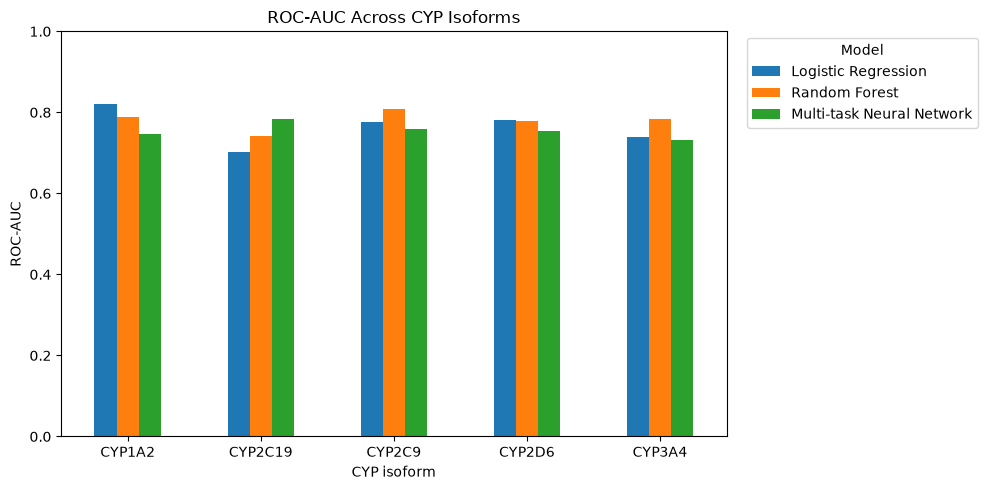

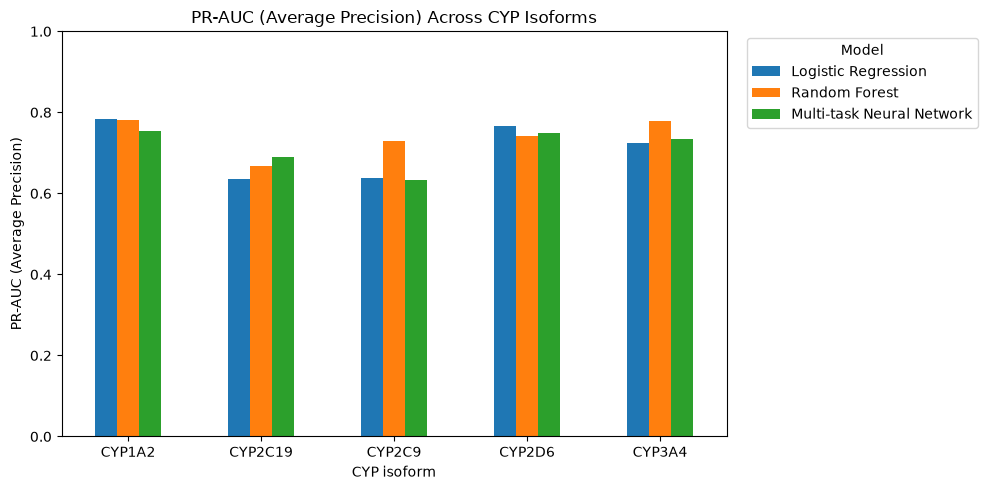

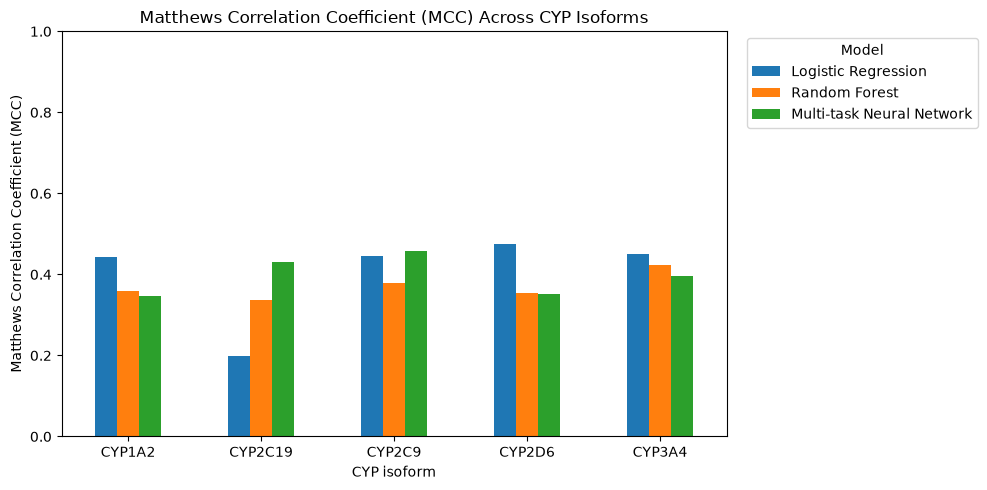

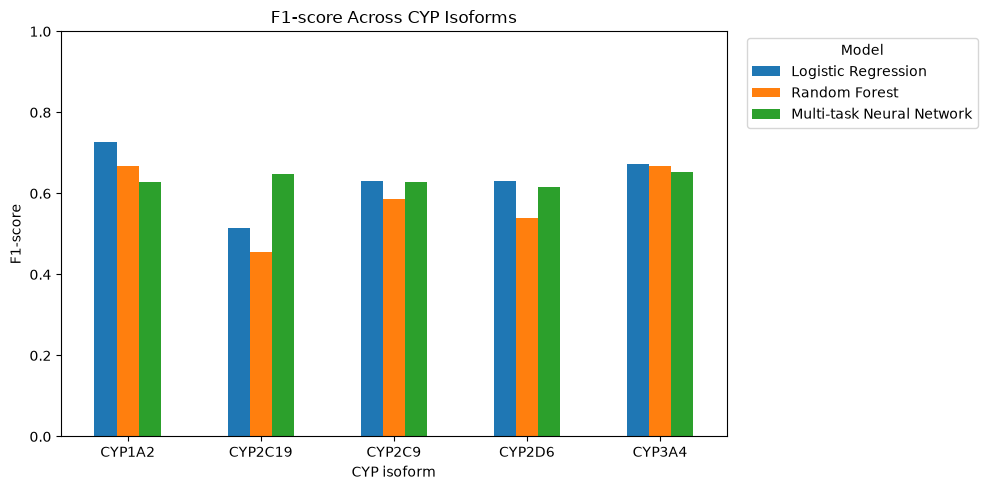

Saved report figures and macro-average table to:
c:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\results


,ROC-AUC,PR-AUC (Average Precision),Matthews Correlation Coefficient (MCC),F1-score
model,,,,
Logistic Regression,0.764281,0.709043,0.402260,0.635179
Random Forest,0.779871,0.739975,0.370897,0.582832
Multi-task Neural Network,0.755099,0.712465,0.396589,0.634253


In [12]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Use the existing project paths.
comparison_path = RESULTS_DIR / "final_model_comparison.csv"
results = pd.read_csv(comparison_path)

model_order = [
    "Logistic Regression",
    "Random Forest",
    "Multi-task Neural Network"
]

metrics = {
    "test_ROC_AUC": "ROC-AUC",
    "test_PR_AUC": "PR-AUC (Average Precision)",
    "test_MCC": "Matthews Correlation Coefficient (MCC)",
    "test_F1": "F1-score"
}

# Plot each metric across the five CYP isoforms.
for metric_col, metric_title in metrics.items():
    pivot = results.pivot(
        index="isoform",
        columns="model",
        values=metric_col
    ).reindex(
        index=["CYP1A2", "CYP2C19", "CYP2C9", "CYP2D6", "CYP3A4"],
        columns=model_order
    )

    ax = pivot.plot(kind="bar", figsize=(10, 5))
    ax.set_title(f"{metric_title} Across CYP Isoforms")
    ax.set_xlabel("CYP isoform")
    ax.set_ylabel(metric_title)
    ax.set_ylim(0, 1)
    ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=0)
    plt.tight_layout()

    filename = metric_col.replace("test_", "").lower()
    plt.savefig(
        RESULTS_DIR / f"comparison_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

# Save a compact macro-average comparison table.
metric_cols = list(metrics.keys())

macro = (
    results.groupby("model")[metric_cols]
    .mean()
    .reindex(model_order)
)

macro.columns = list(metrics.values())

macro.to_csv(RESULTS_DIR / "report_macro_comparison.csv")

print("Saved report figures and macro-average table to:")
print(RESULTS_DIR)
display(macro)


In [13]:

from pathlib import Path

import numpy as np
import pandas as pd

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import GroupShuffleSplit

# Reuse the project paths from your existing notebook.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
RESULTS_DIR = PROJECT_ROOT / "results"

SPLITS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load the cleaned per-isoform records.
df_scaffold = pd.read_csv(
    SPLITS_DIR / "cyp_substrates_global_cold_split.csv"
)

required = {
    "smiles_canonical", "isoform", "label", "global_split"
}
assert required.issubset(df_scaffold.columns), (
    f"Missing columns: {required - set(df_scaffold.columns)}"
)

def get_murcko_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Invalid SMILES encountered: {smiles}")

    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    scaffold_smiles = Chem.MolToSmiles(
        scaffold, canonical=True
    )

    # Acyclic compounds can have an empty Murcko scaffold.
    # Keep these compounds individually grouped by canonical SMILES
    # rather than putting all acyclic compounds into one giant group.
    if not scaffold_smiles:
        return "ACYCLIC::" + smiles

    return scaffold_smiles


# One row per unique canonical compound.
compounds = (
    df_scaffold[["smiles_canonical"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

compounds["scaffold"] = compounds["smiles_canonical"].apply(
    get_murcko_scaffold
)

print("Unique compounds:", len(compounds))
print("Unique scaffold groups:", compounds["scaffold"].nunique())
print("Acyclic compounds:", compounds["scaffold"].str.startswith(
    "ACYCLIC::"
).sum())

# First: 70% train and 30% temporary.
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)

train_idx, temporary_idx = next(
    split1.split(
        compounds,
        groups=compounds["scaffold"]
    )
)

train_compounds = compounds.iloc[train_idx].copy()
temporary_compounds = compounds.iloc[temporary_idx].copy()

# Second: divide the temporary set approximately equally
# into validation and test (~15% each overall).
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=43
)

val_local_idx, test_local_idx = next(
    split2.split(
        temporary_compounds,
        groups=temporary_compounds["scaffold"]
    )
)

val_compounds = temporary_compounds.iloc[val_local_idx].copy()
test_compounds = temporary_compounds.iloc[test_local_idx].copy()

train_compounds["scaffold_split"] = "train"
val_compounds["scaffold_split"] = "val"
test_compounds["scaffold_split"] = "test"

compound_assignments = pd.concat(
    [train_compounds, val_compounds, test_compounds],
    ignore_index=True
)

assert compound_assignments["smiles_canonical"].is_unique
assert compound_assignments["scaffold_split"].notna().all()

# Verify that no scaffold group crosses partitions.
scaffold_partition_counts = (
    compound_assignments.groupby("scaffold")["scaffold_split"]
    .nunique()
)
assert scaffold_partition_counts.max() == 1

# Attach each compound's scaffold assignment to all its CYP records.
df_scaffold = df_scaffold.merge(
    compound_assignments[
        ["smiles_canonical", "scaffold", "scaffold_split"]
    ],
    on="smiles_canonical",
    how="left",
    validate="many_to_one"
)

assert df_scaffold["scaffold_split"].notna().all()

# Save the new split separately; never overwrite the cold split.
df_scaffold.to_csv(
    SPLITS_DIR / "cyp_substrates_scaffold_split.csv",
    index=False
)

compound_assignments.to_csv(
    SPLITS_DIR / "scaffold_compound_assignments.csv",
    index=False
)

# Partition sizes.
split_sizes = (
    compound_assignments["scaffold_split"]
    .value_counts()
    .rename_axis("partition")
    .reset_index(name="unique_compounds")
)

split_sizes["percentage"] = (
    100 * split_sizes["unique_compounds"]
    / len(compound_assignments)
)

print("\nSCAFFOLD SPLIT SIZES")
display(split_sizes)

# Per-isoform label balance.
balance = (
    df_scaffold.groupby(["isoform", "scaffold_split"])
    .agg(
        records=("label", "size"),
        positives=("label", lambda x: int((x == 1).sum())),
        negatives=("label", lambda x: int((x == 0).sum())),
        unique_compounds=("smiles_canonical", "nunique")
    )
    .reset_index()
)

balance["positive_rate"] = (
    balance["positives"] / balance["records"]
)

balance.to_csv(
    RESULTS_DIR / "scaffold_split_class_balance.csv",
    index=False
)

print("\nPER-ISOFORM CLASS BALANCE")
display(balance)

# Explicitly verify scaffold leakage across each partition pair.
partition_scaffolds = {
    part: set(
        compound_assignments.loc[
            compound_assignments["scaffold_split"] == part,
            "scaffold"
        ]
    )
    for part in ["train", "val", "test"]
}

overlap_rows = []

for part_a, part_b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    shared = partition_scaffolds[part_a] & partition_scaffolds[part_b]

    overlap_rows.append({
        "partition_1": part_a,
        "partition_2": part_b,
        "shared_scaffolds": len(shared)
    })

overlap_df = pd.DataFrame(overlap_rows)

overlap_df.to_csv(
    RESULTS_DIR / "scaffold_split_overlap_check.csv",
    index=False
)

print("\nSCAFFOLD OVERLAP CHECK — ALL VALUES MUST BE ZERO")
display(overlap_df)

assert overlap_df["shared_scaffolds"].eq(0).all()

print("\nScaffold split saved successfully.")
print("File:", SPLITS_DIR / "cyp_substrates_scaffold_split.csv")


Unique compounds: 2141
Unique scaffold groups: 1363
Acyclic compounds: 141

SCAFFOLD SPLIT SIZES


,partition,unique_compounds,percentage
0,train,1584,73.984120
1,test,283,13.218122
2,val,274,12.797758



PER-ISOFORM CLASS BALANCE


,isoform,scaffold_split,records,positives,negatives,unique_compounds,positive_rate
0,CYP1A2,test,53,18,35,53,0.339623
1,CYP1A2,train,276,135,141,276,0.489130
2,CYP1A2,val,37,20,17,37,0.540541
3,CYP2C19,test,23,13,10,23,0.565217
4,CYP2C19,train,206,81,125,206,0.393204
5,CYP2C19,val,32,13,19,32,0.406250
6,CYP2C9,test,152,56,96,152,0.368421
7,CYP2C9,train,736,229,507,736,0.311141
8,CYP2C9,val,145,52,93,145,0.358621
9,CYP2D6,test,125,54,71,125,0.432000



SCAFFOLD OVERLAP CHECK — ALL VALUES MUST BE ZERO


,partition_1,partition_2,shared_scaffolds
0,train,val,0
1,train,test,0
2,val,test,0



Scaffold split saved successfully.
File: c:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\data\splits\cyp_substrates_scaffold_split.csv


In [14]:

import numpy as np
import pandas as pd

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    f1_score,
    accuracy_score
)

df_scaffold = pd.read_csv(
    SPLITS_DIR / "cyp_substrates_scaffold_split.csv"
)

ISOFORM_ORDER = ["CYP1A2", "CYP2C19", "CYP2C9", "CYP2D6", "CYP3A4"]

fp_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

def scaffold_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    fp = fp_generator.GetFingerprint(mol)
    arr = np.zeros(2048, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

df_scaffold["fingerprint"] = df_scaffold[
    "smiles_canonical"
].apply(scaffold_fingerprint)

assert df_scaffold["fingerprint"].notna().all()
assert df_scaffold["scaffold_split"].notna().all()

print("Rows:", len(df_scaffold))
print("Unique compounds:", df_scaffold["smiles_canonical"].nunique())
print("Invalid fingerprints:", df_scaffold["fingerprint"].isna().sum())


Rows: 4127
Unique compounds: 2141
Invalid fingerprints: 0


In [15]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

scaffold_metrics = []
scaffold_predictions = []
threshold_grid = np.arange(0.20, 0.81, 0.01)

for isoform in ISOFORM_ORDER:
    subset = df_scaffold[
        df_scaffold["isoform"] == isoform
    ].copy()

    train = subset[subset["scaffold_split"] == "train"]
    val = subset[subset["scaffold_split"] == "val"]
    test = subset[subset["scaffold_split"] == "test"]

    def get_arrays(part):
        X = np.vstack(part["fingerprint"].to_numpy())
        y = part["label"].astype(int).to_numpy()
        return X, y

    X_train, y_train = get_arrays(train)
    X_val, y_val = get_arrays(val)
    X_test, y_test = get_arrays(test)

    assert len(np.unique(y_train)) == 2, f"{isoform}: train class missing"
    assert len(np.unique(y_val)) == 2, f"{isoform}: validation class missing"
    assert len(np.unique(y_test)) == 2, f"{isoform}: test class missing"

    for model_name, estimator in models.items():
        model = estimator
        model.fit(X_train, y_train)

        val_prob = model.predict_proba(X_val)[:, 1]
        test_prob = model.predict_proba(X_test)[:, 1]

        threshold_scores = [
            (
                float(t),
                matthews_corrcoef(y_val, (val_prob >= t).astype(int))
            )
            for t in threshold_grid
        ]

        threshold, val_mcc = max(
            threshold_scores, key=lambda x: x[1]
        )
        test_pred = (test_prob >= threshold).astype(int)

        row = {
            "isoform": isoform,
            "model": model_name,
            "split": "scaffold",
            "n_train": len(y_train),
            "n_val": len(y_val),
            "n_test": len(y_test),
            "threshold_from_validation": threshold,
            "val_MCC": val_mcc,
            "test_ROC_AUC": roc_auc_score(y_test, test_prob),
            "test_PR_AUC": average_precision_score(y_test, test_prob),
            "test_MCC": matthews_corrcoef(y_test, test_pred),
            "test_F1": f1_score(y_test, test_pred, zero_division=0),
            "test_accuracy": accuracy_score(y_test, test_pred)
        }
        scaffold_metrics.append(row)

        for smiles, true_label, prob, pred in zip(
            test["smiles_canonical"].to_numpy(),
            y_test, test_prob, test_pred
        ):
            scaffold_predictions.append({
                "isoform": isoform,
                "model": model_name,
                "smiles_canonical": smiles,
                "y_true": int(true_label),
                "probability_substrate": float(prob),
                "threshold": threshold,
                "prediction": int(pred)
            })

        print(
            f"{isoform} | {model_name} | "
            f"ROC-AUC={row['test_ROC_AUC']:.4f} | "
            f"PR-AUC={row['test_PR_AUC']:.4f} | "
            f"MCC={row['test_MCC']:.4f}"
        )

scaffold_metrics_df = pd.DataFrame(scaffold_metrics)
scaffold_predictions_df = pd.DataFrame(scaffold_predictions)

scaffold_metrics_df.to_csv(
    RESULTS_DIR / "scaffold_single_task_metrics.csv",
    index=False
)
scaffold_predictions_df.to_csv(
    RESULTS_DIR / "scaffold_single_task_predictions.csv",
    index=False
)

print("\nSCAFFOLD-SPLIT METRICS")
display(scaffold_metrics_df)

print("\nMACRO AVERAGES")
display(
    scaffold_metrics_df.groupby("model")[
        ["test_ROC_AUC", "test_PR_AUC", "test_MCC", "test_F1"]
    ].mean()
)


CYP1A2 | Logistic Regression | ROC-AUC=0.7841 | PR-AUC=0.6828 | MCC=0.3458
CYP1A2 | Random Forest | ROC-AUC=0.7857 | PR-AUC=0.7159 | MCC=0.3366
CYP2C19 | Logistic Regression | ROC-AUC=0.7154 | PR-AUC=0.7015 | MCC=0.3750
CYP2C19 | Random Forest | ROC-AUC=0.6923 | PR-AUC=0.6986 | MCC=0.1989
CYP2C9 | Logistic Regression | ROC-AUC=0.7728 | PR-AUC=0.5827 | MCC=0.3485
CYP2C9 | Random Forest | ROC-AUC=0.8133 | PR-AUC=0.7177 | MCC=0.3101
CYP2D6 | Logistic Regression | ROC-AUC=0.7829 | PR-AUC=0.7517 | MCC=0.5406
CYP2D6 | Random Forest | ROC-AUC=0.8136 | PR-AUC=0.8115 | MCC=0.3910
CYP3A4 | Logistic Regression | ROC-AUC=0.6344 | PR-AUC=0.6208 | MCC=0.2218
CYP3A4 | Random Forest | ROC-AUC=0.7134 | PR-AUC=0.7362 | MCC=0.3297

SCAFFOLD-SPLIT METRICS


,isoform,model,split,n_train,n_val,n_test,threshold_from_validation,val_MCC,test_ROC_AUC,test_PR_AUC,test_MCC,test_F1,test_accuracy
0,CYP1A2,Logistic Regression,scaffold,276,37,53,0.78,0.850000,0.784127,0.682757,0.345830,0.578947,0.698113
1,CYP1A2,Random Forest,scaffold,276,37,53,0.51,0.788860,0.785714,0.715865,0.336581,0.600000,0.622642
2,CYP2C19,Logistic Regression,scaffold,206,32,23,0.34,0.472970,0.715385,0.701487,0.375046,0.740741,0.695652
3,CYP2C19,Random Forest,scaffold,206,32,23,0.64,0.485796,0.692308,0.698572,0.198898,0.500000,0.565217
4,CYP2C9,Logistic Regression,scaffold,736,145,152,0.45,0.373125,0.772786,0.582664,0.348539,0.598291,0.690789
5,CYP2C9,Random Forest,scaffold,736,145,152,0.60,0.442672,0.813337,0.717708,0.310065,0.488889,0.697368
6,CYP2D6,Logistic Regression,scaffold,671,120,125,0.51,0.334666,0.782864,0.751736,0.540645,0.730769,0.776000
7,CYP2D6,Random Forest,scaffold,671,120,125,0.67,0.441017,0.813641,0.811531,0.390978,0.428571,0.680000
8,CYP3A4,Logistic Regression,scaffold,1141,202,208,0.39,0.478169,0.634434,0.620835,0.221842,0.608696,0.610577
9,CYP3A4,Random Forest,scaffold,1141,202,208,0.52,0.573629,0.713420,0.736168,0.329661,0.595506,0.653846



MACRO AVERAGES


,test_ROC_AUC,test_PR_AUC,test_MCC,test_F1
model,,,,
Logistic Regression,0.737919,0.667896,0.366380,0.651489
Random Forest,0.763684,0.735969,0.313236,0.522593


In [16]:

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    f1_score,
    accuracy_score
)

# Build one row per compound; missing CYP labels remain NaN.
wide = df_scaffold.pivot_table(
    index="smiles_canonical",
    columns="isoform",
    values="label",
    aggfunc="first"
).reindex(columns=ISOFORM_ORDER)

split_map = df_scaffold.groupby(
    "smiles_canonical"
)["scaffold_split"].first()

scaffold_dataset = wide.copy()
scaffold_dataset["scaffold_split"] = split_map
scaffold_dataset = scaffold_dataset.reset_index()

# Ensure no compound has conflicting scaffold assignments.
assert scaffold_dataset["scaffold_split"].notna().all()
assert scaffold_dataset["smiles_canonical"].is_unique

# Fingerprints are generated for the unique compounds.
X_scaf = np.stack([
    scaffold_fingerprint(s)
    for s in scaffold_dataset["smiles_canonical"]
]).astype(np.float32)

Y_scaf = scaffold_dataset[ISOFORM_ORDER].to_numpy(
    dtype=np.float32
)
M_scaf = np.isfinite(Y_scaf).astype(np.float32)
Y_scaf_filled = np.nan_to_num(Y_scaf, nan=0.0)

split_values = scaffold_dataset["scaffold_split"].to_numpy()
idx_train = np.where(split_values == "train")[0]
idx_val = np.where(split_values == "val")[0]
idx_test = np.where(split_values == "test")[0]

# Verify every isoform has both classes in every partition.
for split_name, idx in [
    ("train", idx_train),
    ("val", idx_val),
    ("test", idx_test)
]:
    for j, iso in enumerate(ISOFORM_ORDER):
        observed = M_scaf[idx, j].astype(bool)
        labels = Y_scaf[idx[observed], j].astype(int)
        assert len(np.unique(labels)) == 2, (
            f"{iso} lacks a class in scaffold {split_name}"
        )

device = torch.device("cpu")
torch.manual_seed(42)
np.random.seed(42)

X_scaf_t = torch.tensor(X_scaf, dtype=torch.float32)
Y_scaf_t = torch.tensor(Y_scaf_filled, dtype=torch.float32)
M_scaf_t = torch.tensor(M_scaf, dtype=torch.float32)

train_dataset_scaf = TensorDataset(
    X_scaf_t[idx_train],
    Y_scaf_t[idx_train],
    M_scaf_t[idx_train]
)

train_loader_scaf = DataLoader(
    train_dataset_scaf,
    batch_size=128,
    shuffle=True
)

# Same architecture as the original multi-task model.
scaffold_model = CYP450MultiTaskNet().to(device)
optimizer_scaf = torch.optim.Adam(
    scaffold_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

def scaffold_masked_loss(logits, targets, mask):
    losses = nn.functional.binary_cross_entropy_with_logits(
        logits, targets, reduction="none"
    )
    return (losses * mask).sum() / mask.sum().clamp(min=1)

def scaffold_predict(indices):
    scaffold_model.eval()
    with torch.no_grad():
        logits = scaffold_model(X_scaf_t[indices])
        return torch.sigmoid(logits).cpu().numpy()

def scaffold_validation_auc():
    probs = scaffold_predict(idx_val)
    aucs = []

    for j in range(len(ISOFORM_ORDER)):
        observed = M_scaf[idx_val, j].astype(bool)
        y_true = Y_scaf[idx_val[observed], j].astype(int)

        if len(np.unique(y_true)) == 2:
            aucs.append(
                roc_auc_score(y_true, probs[observed, j])
            )

    return float(np.mean(aucs))

best_auc_scaf = -np.inf
best_state_scaf = None
best_epoch_scaf = 0
wait_scaf = 0
patience_scaf = 30
history_scaf = []

for epoch in range(1, 301):
    scaffold_model.train()
    total_loss = 0.0
    total_labels = 0

    for xb, yb, mb in train_loader_scaf:
        optimizer_scaf.zero_grad()
        logits = scaffold_model(xb)
        loss = scaffold_masked_loss(logits, yb, mb)
        loss.backward()
        optimizer_scaf.step()

        count = int(mb.sum().item())
        total_loss += loss.item() * count
        total_labels += count

    train_loss = total_loss / max(total_labels, 1)
    val_auc = scaffold_validation_auc()

    history_scaf.append({
        "epoch": epoch,
        "train_masked_bce": train_loss,
        "val_macro_roc_auc": val_auc
    })

    if val_auc > best_auc_scaf + 1e-5:
        best_auc_scaf = val_auc
        best_epoch_scaf = epoch
        best_state_scaf = copy.deepcopy(
            scaffold_model.state_dict()
        )
        wait_scaf = 0
    else:
        wait_scaf += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"train loss={train_loss:.4f} | "
            f"val macro ROC-AUC={val_auc:.4f}"
        )

    if wait_scaf >= patience_scaf:
        print("Early stopping at epoch", epoch)
        break

scaffold_model.load_state_dict(best_state_scaf)

print("\nBest scaffold validation epoch:", best_epoch_scaf)
print("Best validation macro ROC-AUC:", round(best_auc_scaf, 4))

pd.DataFrame(history_scaf).to_csv(
    RESULTS_DIR / "scaffold_multitask_training_history.csv",
    index=False
)

torch.save(
    {
        "model_state_dict": scaffold_model.state_dict(),
        "isoforms": ISOFORM_ORDER,
        "input_dim": 2048,
        "best_epoch": best_epoch_scaf,
        "best_validation_macro_roc_auc": best_auc_scaf,
        "seed": 42,
        "split": "scaffold"
    },
    MODELS_DIR / "cyp450_multitask_scaffold.pt"
)

# Select thresholds on validation data; evaluate only once on test.
val_probs_scaf = scaffold_predict(idx_val)
test_probs_scaf = scaffold_predict(idx_test)

threshold_grid = np.arange(0.20, 0.81, 0.01)
scaffold_mt_rows = []
thresholds_scaf = {}

for j, iso in enumerate(ISOFORM_ORDER):
    val_observed = M_scaf[idx_val, j].astype(bool)
    yv = Y_scaf[idx_val[val_observed], j].astype(int)
    pv = val_probs_scaf[val_observed, j]

    choices = [
        (
            float(t),
            matthews_corrcoef(yv, (pv >= t).astype(int))
        )
        for t in threshold_grid
    ]
    threshold, val_mcc = max(choices, key=lambda z: z[1])
    thresholds_scaf[iso] = threshold

    test_observed = M_scaf[idx_test, j].astype(bool)
    yt = Y_scaf[idx_test[test_observed], j].astype(int)
    pt = test_probs_scaf[test_observed, j]
    yp = (pt >= threshold).astype(int)

    scaffold_mt_rows.append({
        "isoform": iso,
        "model": "Multi-task Neural Network",
        "split": "scaffold",
        "n_test": len(yt),
        "threshold_from_validation": threshold,
        "val_MCC": val_mcc,
        "test_ROC_AUC": roc_auc_score(yt, pt),
        "test_PR_AUC": average_precision_score(yt, pt),
        "test_MCC": matthews_corrcoef(yt, yp),
        "test_F1": f1_score(yt, yp, zero_division=0),
        "test_accuracy": accuracy_score(yt, yp)
    })

scaffold_mt_metrics = pd.DataFrame(scaffold_mt_rows)
scaffold_mt_metrics.to_csv(
    RESULTS_DIR / "scaffold_multitask_metrics.csv",
    index=False
)

print("\nSCAFFOLD MULTI-TASK TEST RESULTS")
display(scaffold_mt_metrics)

print("\nMACRO AVERAGES")
display(
    scaffold_mt_metrics[
        ["test_ROC_AUC", "test_PR_AUC", "test_MCC",
         "test_F1", "test_accuracy"]
    ].mean().to_frame("macro_average")
)


Epoch 001 | train loss=0.6706 | val macro ROC-AUC=0.7119
Epoch 010 | train loss=0.0457 | val macro ROC-AUC=0.7816
Epoch 020 | train loss=0.0184 | val macro ROC-AUC=0.7776
Epoch 030 | train loss=0.0138 | val macro ROC-AUC=0.7761
Early stopping at epoch 36

Best scaffold validation epoch: 6
Best validation macro ROC-AUC: 0.7905

SCAFFOLD MULTI-TASK TEST RESULTS


,isoform,model,split,n_test,threshold_from_validation,val_MCC,test_ROC_AUC,test_PR_AUC,test_MCC,test_F1,test_accuracy
0,CYP1A2,Multi-task Neural Network,scaffold,53,0.56,0.695278,0.709524,0.484072,0.396520,0.615385,0.716981
1,CYP2C19,Multi-task Neural Network,scaffold,23,0.41,0.625577,0.592308,0.706450,0.137409,0.583333,0.565217
2,CYP2C9,Multi-task Neural Network,scaffold,152,0.61,0.418064,0.783761,0.605314,0.321048,0.530612,0.697368
3,CYP2D6,Multi-task Neural Network,scaffold,125,0.75,0.377463,0.818336,0.802316,0.540097,0.720000,0.776000
4,CYP3A4,Multi-task Neural Network,scaffold,208,0.26,0.512698,0.656909,0.655708,0.221881,0.649351,0.610577



MACRO AVERAGES


,macro_average
test_ROC_AUC,0.712168
test_PR_AUC,0.650772
test_MCC,0.323391
test_F1,0.619736
test_accuracy,0.673229


In [17]:

from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import numpy as np

structural_rows = []

for isoform in ISOFORM_ORDER:
    subset = df_scaffold[
        df_scaffold["isoform"] == isoform
    ].copy()

    train = subset[subset["scaffold_split"] == "train"]

    X_train = np.vstack(train["fingerprint"].to_numpy())
    y_train = train["label"].astype(int).to_numpy()

    rf = RandomForestClassifier(
        n_estimators=500,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)

    importances = rf.feature_importances_
    top_indices = np.argsort(importances)[::-1][:20]

    for rank, bit_index in enumerate(top_indices, start=1):
        structural_rows.append({
            "isoform": isoform,
            "rank": rank,
            "fingerprint_bit": int(bit_index),
            "importance": float(importances[bit_index])
        })

importance_df = pd.DataFrame(structural_rows)

importance_df.to_csv(
    RESULTS_DIR / "scaffold_rf_top_fingerprint_bits.csv",
    index=False
)

print("Top fingerprint features saved.")
for isoform in ISOFORM_ORDER:
    print(f"\n{isoform}")
    display(
        importance_df[importance_df["isoform"] == isoform]
        .head(10)
    )


Top fingerprint features saved.

CYP1A2


,isoform,rank,fingerprint_bit,importance
0,CYP1A2,1,389,0.029499
1,CYP1A2,2,807,0.021078
2,CYP1A2,3,1380,0.019170
3,CYP1A2,4,1873,0.015571
4,CYP1A2,5,1057,0.014546
5,CYP1A2,6,881,0.011859
6,CYP1A2,7,1453,0.010704
7,CYP1A2,8,1844,0.010372
8,CYP1A2,9,650,0.010091
9,CYP1A2,10,1750,0.009643



CYP2C19


,isoform,rank,fingerprint_bit,importance
20,CYP2C19,1,1057,0.025341
21,CYP2C19,2,807,0.018756
22,CYP2C19,3,1145,0.016046
23,CYP2C19,4,1060,0.015968
24,CYP2C19,5,1917,0.015786
25,CYP2C19,6,881,0.013813
26,CYP2C19,7,1171,0.012879
27,CYP2C19,8,1163,0.012743
28,CYP2C19,9,294,0.009481
29,CYP2C19,10,935,0.008965



CYP2C9


,isoform,rank,fingerprint_bit,importance
40,CYP2C9,1,1019,0.008964
41,CYP2C9,2,1171,0.008530
42,CYP2C9,3,679,0.007628
43,CYP2C9,4,932,0.007073
44,CYP2C9,5,1060,0.006073
45,CYP2C9,6,1,0.005986
46,CYP2C9,7,1199,0.005921
47,CYP2C9,8,1574,0.005496
48,CYP2C9,9,283,0.005324
49,CYP2C9,10,534,0.005316



CYP2D6


,isoform,rank,fingerprint_bit,importance
60,CYP2D6,1,650,0.027094
61,CYP2D6,2,314,0.016736
62,CYP2D6,3,1917,0.013421
63,CYP2D6,4,1750,0.012594
64,CYP2D6,5,389,0.010408
65,CYP2D6,6,781,0.010106
66,CYP2D6,7,807,0.009563
67,CYP2D6,8,1647,0.009073
68,CYP2D6,9,1536,0.008838
69,CYP2D6,10,378,0.008467



CYP3A4


,isoform,rank,fingerprint_bit,importance
80,CYP3A4,1,926,0.015649
81,CYP3A4,2,1060,0.014046
82,CYP3A4,3,1057,0.011908
83,CYP3A4,4,881,0.009859
84,CYP3A4,5,1162,0.009122
85,CYP3A4,6,1145,0.008661
86,CYP3A4,7,1844,0.007913
87,CYP3A4,8,1683,0.006939
88,CYP3A4,9,1274,0.006808
89,CYP3A4,10,1699,0.006614


In [18]:

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
import pandas as pd
import numpy as np

bit_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

# Use only the scaffold training partition for interpretation.
train_records = df_scaffold[
    df_scaffold["scaffold_split"] == "train"
].copy()

fragment_rows = []

for isoform in ISOFORM_ORDER:
    top_bits = (
        importance_df[importance_df["isoform"] == isoform]
        .sort_values("importance", ascending=False)
        .head(10)
    )

    isoform_records = train_records[
        train_records["isoform"] == isoform
    ]

    # Record one representative example for each important bit.
    for _, bit_row in top_bits.iterrows():
        bit_id = int(bit_row["fingerprint_bit"])
        found = False

        for _, record in isoform_records.iterrows():
            smiles = record["smiles_canonical"]
            mol = Chem.MolFromSmiles(smiles)

            if mol is None:
                continue

            additional = rdFingerprintGenerator.AdditionalOutput()
            additional.AllocateBitInfoMap()

            bit_generator.GetFingerprint(
                mol,
                additionalOutput=additional
            )

            bit_info = additional.GetBitInfoMap()

            if bit_id not in bit_info:
                continue

            atom_idx, radius = bit_info[bit_id][0]

            if radius == 0:
                atom_ids = [atom_idx]
                bond_ids = []
            else:
                bond_ids = list(
                    Chem.FindAtomEnvironmentOfRadiusN(
                        mol, radius, atom_idx
                    )
                )

                atom_set = {atom_idx}
                for bond_id in bond_ids:
                    bond = mol.GetBondWithIdx(bond_id)
                    atom_set.add(bond.GetBeginAtomIdx())
                    atom_set.add(bond.GetEndAtomIdx())

                atom_ids = sorted(atom_set)

            fragment_smiles = Chem.MolFragmentToSmiles(
                mol,
                atomsToUse=atom_ids,
                bondsToUse=bond_ids,
                canonical=True,
                isomericSmiles=True
            )

            fragment_rows.append({
                "isoform": isoform,
                "fingerprint_bit": bit_id,
                "importance": float(bit_row["importance"]),
                "representative_smiles": smiles,
                "radius": int(radius),
                "center_atom_index": int(atom_idx),
                "fragment_smiles": fragment_smiles
            })

            found = True
            break

        if not found:
            fragment_rows.append({
                "isoform": isoform,
                "fingerprint_bit": bit_id,
                "importance": float(bit_row["importance"]),
                "representative_smiles": None,
                "radius": None,
                "center_atom_index": None,
                "fragment_smiles": None
            })

fragment_df = pd.DataFrame(fragment_rows)

fragment_df.to_csv(
    RESULTS_DIR / "important_fingerprint_fragments.csv",
    index=False
)

print("Saved mapped fingerprint fragments.")
display(
    fragment_df[
        [
            "isoform",
            "fingerprint_bit",
            "importance",
            "fragment_smiles",
            "radius"
        ]
    ]
)


Saved mapped fingerprint fragments.


,isoform,fingerprint_bit,importance,fragment_smiles,radius
0,CYP1A2,389,0.029499,CO,1
1,CYP1A2,807,0.021078,O,0
2,CYP1A2,1380,0.019170,C,0
3,CYP1A2,1873,0.015571,c,0
4,CYP1A2,1057,0.014546,C,0
5,CYP1A2,881,0.011859,N,0
6,CYP1A2,1453,0.010704,CF,1
7,CYP1A2,1844,0.010372,C[C@@H](O)[C@@H](O)[C@H](O)C,2
8,CYP1A2,650,0.010091,O,0
9,CYP1A2,1750,0.009643,ccc,1


In [19]:

from pathlib import Path
import pandas as pd
import numpy as np

# Find the project root whether the notebook runs from
# the project directory or its notebooks/ subdirectory.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results"

print("Project root:", PROJECT_ROOT.resolve())
print("Results directory:", RESULTS_DIR.resolve())
print("Results directory exists:", RESULTS_DIR.exists())

# Locate the prediction and metric files recursively.
for path in sorted(RESULTS_DIR.rglob("*.csv")):
    print(path.relative_to(PROJECT_ROOT))


Project root: C:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability
Results directory: C:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\results
Results directory exists: True
results\all_isoform_baseline_metrics.csv
results\all_isoform_baseline_predictions.csv
results\balanced_multitask_macro_metrics.csv
results\balanced_multitask_test_metrics.csv
results\balanced_multitask_test_predictions.csv
results\balanced_multitask_training_history.csv
results\cyp1a2_baseline_comparison.csv
results\cyp1a2_logistic_regression_metrics.csv
results\cyp1a2_logistic_regression_predictions.csv
results\cyp1a2_random_forest_metrics.csv
results\final_model_comparison.csv
results\important_fingerprint_fragments.csv
results\macro_average_model_comparison.csv
results\metrics\applicability_domain_summary.csv
results\metrics\chirality_fingerprint_comparison.csv
results\metrics\cross_isoform_partition_overlap_details.csv
results\metrics\cross_partition_compounds.csv
results\metrics

In [20]:

from pathlib import Path
import pandas as pd
from IPython.display import display

wanted = [
    "all_isoform_baseline_predictions.csv",
    "multitask_test_predictions.csv",
    "balanced_multitask_test_predictions.csv",
    "scaffold_single_task_predictions.csv",
    "scaffold_multitask_metrics.csv",
]

for filename in wanted:
    matches = list(RESULTS_DIR.rglob(filename))
    print(f"\n{'=' * 60}\n{filename}")

    if not matches:
        print("Not found under:", RESULTS_DIR.resolve())
        continue

    for path in matches:
        data = pd.read_csv(path)
        print("Path:", path.relative_to(PROJECT_ROOT))
        print("Shape:", data.shape)
        print("Columns:", data.columns.tolist())
        display(data.head(3))



all_isoform_baseline_predictions.csv
Path: results\all_isoform_baseline_predictions.csv
Shape: (1194, 7)
Columns: ['isoform', 'model', 'smiles_canonical', 'y_true', 'probability_substrate', 'threshold', 'prediction']


,isoform,model,smiles_canonical,y_true,probability_substrate,threshold,prediction
0,CYP1A2,Morgan2048_LogisticRegression,Cc1cc2c(s1)Nc1ccccc1N=C2N1CCN(C)CC1,1,0.888450,0.27,1
1,CYP1A2,Morgan2048_LogisticRegression,CN1C(=O)CN=C(c2ccccc2F)c2cc([N+](=O)[O-])ccc21,1,0.904768,0.27,1
2,CYP1A2,Morgan2048_LogisticRegression,O=C(O)C(S)C(S)C(=O)O,0,0.043427,0.27,0



multitask_test_predictions.csv
Path: results\multitask_test_predictions.csv
Shape: (597, 6)
Columns: ['isoform', 'smiles_canonical', 'y_true', 'probability_substrate', 'threshold', 'prediction']


,isoform,smiles_canonical,y_true,probability_substrate,threshold,prediction
0,CYP1A2,C#CCN[C@@H]1CCc2ccccc21,1,0.994905,0.62,1
1,CYP1A2,C=C[C@H]1CN2CC[C@H]1C[C@H]2[C@H](O)c1ccnc2ccc(...,1,0.426250,0.62,0
2,CYP1A2,CC(=O)OC[C@@H]1CS[C@H]2C(NC(=O)CCCCC(NC(=O)C[N...,0,0.000005,0.62,0



balanced_multitask_test_predictions.csv
Path: results\balanced_multitask_test_predictions.csv
Shape: (597, 6)
Columns: ['isoform', 'smiles_canonical', 'y_true', 'probability_substrate', 'threshold', 'prediction']


,isoform,smiles_canonical,y_true,probability_substrate,threshold,prediction
0,CYP1A2,C#CCN[C@@H]1CCc2ccccc21,1,0.907183,0.25,1
1,CYP1A2,C=C[C@H]1CN2CC[C@H]1C[C@H]2[C@H](O)c1ccnc2ccc(...,1,0.376362,0.25,1
2,CYP1A2,CC(=O)OC[C@@H]1CS[C@H]2C(NC(=O)CCCCC(NC(=O)C[N...,0,0.018415,0.25,0



scaffold_single_task_predictions.csv
Path: results\scaffold_single_task_predictions.csv
Shape: (1122, 7)
Columns: ['isoform', 'model', 'smiles_canonical', 'y_true', 'probability_substrate', 'threshold', 'prediction']


,isoform,model,smiles_canonical,y_true,probability_substrate,threshold,prediction
0,CYP1A2,Logistic Regression,c1ccc([C@@H]2CO2)cc1,0,0.346662,0.78,0
1,CYP1A2,Logistic Regression,NC(CCSC(F)F)C(=O)O,0,0.026630,0.78,0
2,CYP1A2,Logistic Regression,CC[C@H](OC(C)=O)C(C[C@@H](C)N(C)C)(c1ccccc1)c1...,0,0.554853,0.78,0



scaffold_multitask_metrics.csv
Path: results\scaffold_multitask_metrics.csv
Shape: (5, 11)
Columns: ['isoform', 'model', 'split', 'n_test', 'threshold_from_validation', 'val_MCC', 'test_ROC_AUC', 'test_PR_AUC', 'test_MCC', 'test_F1', 'test_accuracy']


,isoform,model,split,n_test,threshold_from_validation,val_MCC,test_ROC_AUC,test_PR_AUC,test_MCC,test_F1,test_accuracy
0,CYP1A2,Multi-task Neural Network,scaffold,53,0.56,0.695278,0.709524,0.484072,0.396520,0.615385,0.716981
1,CYP2C19,Multi-task Neural Network,scaffold,23,0.41,0.625577,0.592308,0.706450,0.137409,0.583333,0.565217
2,CYP2C9,Multi-task Neural Network,scaffold,152,0.61,0.418064,0.783761,0.605314,0.321048,0.530612,0.697368


In [21]:

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

METRICS_DIR = RESULTS_DIR / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

prediction_files = {
    "cold_compound_baselines": RESULTS_DIR / "all_isoform_baseline_predictions.csv",
    "cold_compound_multitask": RESULTS_DIR / "multitask_test_predictions.csv",
    "cold_compound_balanced_multitask": RESULTS_DIR / "balanced_multitask_test_predictions.csv",
    "scaffold_baselines": RESULTS_DIR / "scaffold_single_task_predictions.csv",
}

summary_rows = []
error_frames = []

for protocol, path in prediction_files.items():
    if not path.exists():
        print(f"Skipping missing file: {path}")
        continue

    df = pd.read_csv(path)

    required = {"isoform", "y_true", "prediction"}
    if not required.issubset(df.columns):
        print(f"Skipping {path.name}; missing columns: {required - set(df.columns)}")
        continue

    for isoform, group in df.groupby("isoform"):
        y_true = group["y_true"].astype(int)
        y_pred = group["prediction"].astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        summary_rows.append({
            "protocol": protocol,
            "model": group["model"].iloc[0] if "model" in group.columns else protocol,
            "isoform": isoform,
            "n": len(group),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "sensitivity_recall": tp / (tp + fn) if tp + fn else np.nan,
            "specificity": tn / (tn + fp) if tn + fp else np.nan,
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "error_rate": (fp + fn) / len(group) if len(group) else np.nan,
        })

        mistakes = group.loc[y_true.to_numpy() != y_pred.to_numpy()].copy()
        mistakes["protocol"] = protocol
        mistakes["error_type"] = np.where(
            mistakes["y_true"].astype(int) == 1,
            "False negative: actual substrate predicted non-substrate",
            "False positive: actual non-substrate predicted substrate",
        )
        error_frames.append(mistakes)

error_summary = pd.DataFrame(summary_rows)
if not error_summary.empty:
    summary_path = METRICS_DIR / "error_analysis_summary.csv"
    error_summary.to_csv(summary_path, index=False)

    print("Saved:", summary_path)
    display(
        error_summary.sort_values(["protocol", "isoform"])
        .round(3)
    )

if error_frames:
    all_errors = pd.concat(error_frames, ignore_index=True)
    errors_path = METRICS_DIR / "misclassified_test_compounds.csv"
    all_errors.to_csv(errors_path, index=False)

    print("\nSaved individual errors:", errors_path)
    print("Total misclassified prediction rows:", len(all_errors))
    display(
        all_errors[
            [c for c in [
                "protocol", "model", "isoform", "error_type",
                "y_true", "prediction", "probability_substrate",
                "threshold", "smiles_canonical"
            ] if c in all_errors.columns]
        ].head(15)
    )


Saved: c:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\results\metrics\error_analysis_summary.csv


,protocol,model,isoform,n,TN,FP,FN,TP,sensitivity_recall,specificity,precision,error_rate
10,cold_compound_balanced_multitask,cold_compound_balanced_multitask,CYP1A2,59,18,14,5,22,0.815,0.562,0.611,0.322
11,cold_compound_balanced_multitask,cold_compound_balanced_multitask,CYP2C19,43,23,5,5,10,0.667,0.821,0.667,0.233
12,cold_compound_balanced_multitask,cold_compound_balanced_multitask,CYP2C9,137,71,22,25,19,0.432,0.763,0.463,0.343
13,cold_compound_balanced_multitask,cold_compound_balanced_multitask,CYP2D6,124,56,10,32,26,0.448,0.848,0.722,0.339
14,cold_compound_balanced_multitask,cold_compound_balanced_multitask,CYP3A4,234,91,34,48,61,0.560,0.728,0.642,0.350
0,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,118,38,26,11,43,0.796,0.594,0.623,0.314
1,cold_compound_baselines,Morgan2048_LogisticRegression,CYP2C19,86,43,13,16,14,0.467,0.768,0.519,0.337
2,cold_compound_baselines,Morgan2048_LogisticRegression,CYP2C9,274,146,40,32,56,0.636,0.785,0.583,0.263
3,cold_compound_baselines,Morgan2048_LogisticRegression,CYP2D6,248,120,12,63,53,0.457,0.909,0.815,0.302
4,cold_compound_baselines,Morgan2048_LogisticRegression,CYP3A4,468,204,46,85,133,0.610,0.816,0.743,0.280



Saved individual errors: c:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\results\metrics\misclassified_test_compounds.csv
Total misclassified prediction rows: 1084


,protocol,model,isoform,error_type,y_true,prediction,probability_substrate,threshold,smiles_canonical
0,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,False positive: actual non-substrate predicted...,0,1,0.503463,0.27,CC(Cc1ccccc1)NN
1,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,False positive: actual non-substrate predicted...,0,1,0.486055,0.27,CCOC(=O)C(CCc1ccccc1)NC1CS[C@H](c2cccs2)CN(CC(...
2,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,False positive: actual non-substrate predicted...,0,1,0.804230,0.27,CC(C)Cc1ccc(C(C)C(O)=NO)cc1
3,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,False positive: actual non-substrate predicted...,0,1,0.703828,0.27,O=C(O)c1cn(-c2ccc(F)cc2)c2cc(N3CCNCC3)c(F)cc2c1=O
4,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,False positive: actual non-substrate predicted...,0,1,0.823598,0.27,CCn1cc(C(=O)O)c(=O)c2ccc(C)nc21
5,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,False negative: actual substrate predicted non...,1,0,0.180862,0.27,COc1cc([C@@H]2c3cc4c(cc3[C@@H](O[C@@H]3O[C@@H]...
6,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,False positive: actual non-substrate predicted...,0,1,0.387731,0.27,CO[C@@H]1[C@H](O)[C@@H](O)[C@H](C)O[C@@H]1O
7,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,False positive: actual non-substrate predicted...,0,1,0.393467,0.27,O=C1NC(=O)C(c2ccc(Oc3ccccc3)cc2)(N2CCN(c3ncccn...
8,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,False positive: actual non-substrate predicted...,0,1,0.666002,0.27,CC(C)N=c1cc2n(-c3ccc(Cl)cc3)c3ccccc3nc-2cc1Nc1...
9,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,False positive: actual non-substrate predicted...,0,1,0.805626,0.27,Cn1c(=O)ccc2ccccc21


In [22]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import confusion_matrix

METRICS_DIR = RESULTS_DIR / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

prediction_files = {
    "cold_compound_baselines": RESULTS_DIR / "all_isoform_baseline_predictions.csv",
    "cold_compound_multitask": RESULTS_DIR / "multitask_test_predictions.csv",
    "cold_compound_balanced_multitask": RESULTS_DIR / "balanced_multitask_test_predictions.csv",
    "scaffold_baselines": RESULTS_DIR / "scaffold_single_task_predictions.csv",
}

summary_rows = []
error_frames = []

for protocol, path in prediction_files.items():
    if not path.exists():
        print("Skipping missing file:", path)
        continue

    df = pd.read_csv(path)

    if "model" not in df.columns:
        df["model"] = protocol

    for (model, isoform), group in df.groupby(["model", "isoform"]):
        y_true = group["y_true"].astype(int).to_numpy()
        y_pred = group["prediction"].astype(int).to_numpy()

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        summary_rows.append({
            "protocol": protocol,
            "model": model,
            "isoform": isoform,
            "n": len(group),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "specificity": tn / (tn + fp) if tn + fp else np.nan,
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "error_rate": (fp + fn) / len(group) if len(group) else np.nan,
        })

        mistakes = group.loc[y_true != y_pred].copy()
        mistakes["protocol"] = protocol
        mistakes["error_type"] = np.where(
            mistakes["y_true"].astype(int) == 1,
            "False negative",
            "False positive"
        )
        error_frames.append(mistakes)

summary = pd.DataFrame(summary_rows)
summary.to_csv(METRICS_DIR / "error_analysis_summary_corrected.csv", index=False)

print("Corrected summary saved.")
display(summary.round(3))

if error_frames:
    errors = pd.concat(error_frames, ignore_index=True)
    errors.to_csv(
        METRICS_DIR / "misclassified_test_compounds_corrected.csv",
        index=False
    )
    print("Corrected individual errors saved.")
    print("Total incorrect prediction rows:", len(errors))


Corrected summary saved.


,protocol,model,isoform,n,TN,FP,FN,TP,recall,specificity,precision,error_rate
0,cold_compound_baselines,Morgan2048_LogisticRegression,CYP1A2,59,17,15,3,24,0.889,0.531,0.615,0.305
1,cold_compound_baselines,Morgan2048_LogisticRegression,CYP2C19,43,17,11,6,9,0.600,0.607,0.450,0.395
2,cold_compound_baselines,Morgan2048_LogisticRegression,CYP2C9,137,74,19,15,29,0.659,0.796,0.604,0.248
3,cold_compound_baselines,Morgan2048_LogisticRegression,CYP2D6,124,61,5,29,29,0.500,0.924,0.853,0.274
4,cold_compound_baselines,Morgan2048_LogisticRegression,CYP3A4,234,104,21,43,66,0.606,0.832,0.759,0.274
5,cold_compound_baselines,Morgan2048_RandomForest,CYP1A2,59,21,11,8,19,0.704,0.656,0.633,0.322
6,cold_compound_baselines,Morgan2048_RandomForest,CYP2C19,43,26,2,10,5,0.333,0.929,0.714,0.279
7,cold_compound_baselines,Morgan2048_RandomForest,CYP2C9,137,72,21,17,27,0.614,0.774,0.562,0.277
8,cold_compound_baselines,Morgan2048_RandomForest,CYP2D6,124,59,7,34,24,0.414,0.894,0.774,0.331
9,cold_compound_baselines,Morgan2048_RandomForest,CYP3A4,234,100,25,42,67,0.615,0.800,0.728,0.286


Corrected individual errors saved.
Total incorrect prediction rows: 1084


In [23]:

for path in [
    PROJECT_ROOT / "data" / "processed" / "cyp_substrates_cleaned.csv",
    PROJECT_ROOT / "data" / "splits" / "cyp_substrates_global_cold_split.csv",
    PROJECT_ROOT / "data" / "splits" / "cyp_substrates_scaffold_split.csv",
]:
    print(path.exists(), path)


True c:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\data\processed\cyp_substrates_cleaned.csv
True c:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\data\splits\cyp_substrates_global_cold_split.csv
True c:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\data\splits\cyp_substrates_scaffold_split.csv


In [24]:

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

clean_path = PROJECT_ROOT / "data" / "processed" / "cyp_substrates_cleaned.csv"
cold_path = PROJECT_ROOT / "data" / "splits" / "cyp_substrates_global_cold_split.csv"
scaffold_path = PROJECT_ROOT / "data" / "splits" / "cyp_substrates_scaffold_split.csv"

clean = pd.read_csv(clean_path)
cold = pd.read_csv(cold_path)
scaffold = pd.read_csv(scaffold_path)

print("Cleaned columns:", clean.columns.tolist())
print("Cold-split columns:", cold.columns.tolist())
print("Scaffold-split columns:", scaffold.columns.tolist())


Cleaned columns: ['source_file', 'source_row_index', 'isoform', 'split', 'smiles_original', 'label', 'group', 'smiles_canonical']
Cold-split columns: ['source_file', 'source_row_index', 'isoform', 'split', 'smiles_original', 'label', 'group', 'smiles_canonical', 'global_split']
Scaffold-split columns: ['source_file', 'source_row_index', 'isoform', 'split', 'smiles_original', 'label', 'group', 'smiles_canonical', 'global_split', 'scaffold', 'scaffold_split']


In [25]:

from pathlib import Path
import pandas as pd
import numpy as np
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

METRICS_DIR = RESULTS_DIR / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

cold = pd.read_csv(
    PROJECT_ROOT / "data" / "splits" / "cyp_substrates_global_cold_split.csv"
)
scaffold = pd.read_csv(
    PROJECT_ROOT / "data" / "splits" / "cyp_substrates_scaffold_split.csv"
)

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048
)

def make_fingerprint(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    return generator.GetFingerprint(mol) if mol is not None else None

def evaluate_similarity(split_df, split_col, protocol):
    rows = []

    for isoform in sorted(split_df["isoform"].dropna().unique()):
        subset = split_df[split_df["isoform"] == isoform]

        train_smiles = (
            subset.loc[subset[split_col] == "train", "smiles_canonical"]
            .dropna().unique()
        )
        test = subset.loc[
            subset[split_col] == "test",
            ["isoform", "smiles_canonical", "label"]
        ].drop_duplicates(["isoform", "smiles_canonical"])

        train_fps = [
            fp for s in train_smiles
            if (fp := make_fingerprint(s)) is not None
        ]

        print(
            f"{protocol} | {isoform}: "
            f"{len(train_fps)} training fingerprints, "
            f"{len(test)} unique test compounds"
        )

        for _, row in test.iterrows():
            test_fp = make_fingerprint(row["smiles_canonical"])
            if test_fp is None or not train_fps:
                max_similarity = np.nan
            else:
                similarities = DataStructs.BulkTanimotoSimilarity(
                    test_fp, train_fps
                )
                max_similarity = max(similarities)

            rows.append({
                "protocol": protocol,
                "isoform": isoform,
                "smiles_canonical": row["smiles_canonical"],
                "label": row["label"],
                "max_train_tanimoto": max_similarity,
            })

    return pd.DataFrame(rows)

cold_similarity = evaluate_similarity(
    cold, "global_split", "cold_compound"
)
scaffold_similarity = evaluate_similarity(
    scaffold, "scaffold_split", "scaffold"
)

similarity_df = pd.concat(
    [cold_similarity, scaffold_similarity],
    ignore_index=True
)

similarity_path = METRICS_DIR / "test_compound_applicability_domain.csv"
similarity_df.to_csv(similarity_path, index=False)

summary = (
    similarity_df.groupby(["protocol", "isoform"])["max_train_tanimoto"]
    .agg(
        n="count",
        mean="mean",
        median="median",
        q10=lambda x: x.quantile(0.10),
        q90=lambda x: x.quantile(0.90),
        minimum="min",
    )
    .reset_index()
)

summary_path = METRICS_DIR / "applicability_domain_summary.csv"
summary.to_csv(summary_path, index=False)

print("\nSaved:", similarity_path)
print("Saved:", summary_path)
display(summary.round(3))


cold_compound | CYP1A2: 253 training fingerprints, 59 unique test compounds
cold_compound | CYP2C19: 172 training fingerprints, 43 unique test compounds
cold_compound | CYP2C9: 744 training fingerprints, 137 unique test compounds
cold_compound | CYP2D6: 655 training fingerprints, 124 unique test compounds
cold_compound | CYP3A4: 1090 training fingerprints, 234 unique test compounds
scaffold | CYP1A2: 276 training fingerprints, 53 unique test compounds
scaffold | CYP2C19: 206 training fingerprints, 23 unique test compounds
scaffold | CYP2C9: 736 training fingerprints, 152 unique test compounds
scaffold | CYP2D6: 671 training fingerprints, 125 unique test compounds
scaffold | CYP3A4: 1141 training fingerprints, 208 unique test compounds

Saved: c:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\results\metrics\test_compound_applicability_domain.csv
Saved: c:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\results\metrics\applicability_domain_summary.csv


,protocol,isoform,n,mean,median,q10,q90,minimum
0,cold_compound,CYP1A2,59,0.321,0.267,0.211,0.482,0.163
1,cold_compound,CYP2C19,43,0.318,0.286,0.192,0.448,0.153
2,cold_compound,CYP2C9,137,0.626,0.612,0.269,1.000,0.173
3,cold_compound,CYP2D6,124,0.477,0.445,0.250,0.752,0.161
4,cold_compound,CYP3A4,234,0.542,0.474,0.263,1.000,0.175
5,scaffold,CYP1A2,53,0.307,0.269,0.213,0.454,0.177
6,scaffold,CYP2C19,23,0.322,0.289,0.204,0.460,0.153
7,scaffold,CYP2C9,152,0.487,0.394,0.246,1.000,0.183
8,scaffold,CYP2D6,125,0.422,0.377,0.259,0.651,0.183
9,scaffold,CYP3A4,208,0.450,0.383,0.249,0.730,0.167


In [26]:

errors_path = METRICS_DIR / "misclassified_test_compounds_corrected.csv"
errors = pd.read_csv(errors_path)

prediction_files = {
    "cold_compound_baselines": RESULTS_DIR / "all_isoform_baseline_predictions.csv",
    "cold_compound_multitask": RESULTS_DIR / "multitask_test_predictions.csv",
    "cold_compound_balanced_multitask": RESULTS_DIR / "balanced_multitask_test_predictions.csv",
    "scaffold_baselines": RESULTS_DIR / "scaffold_single_task_predictions.csv",
}

prediction_frames = []
for protocol, path in prediction_files.items():
    if not path.exists():
        continue
    df = pd.read_csv(path)
    if "model" not in df.columns:
        df["model"] = protocol
    df["protocol"] = protocol
    prediction_frames.append(df)

predictions = pd.concat(prediction_frames, ignore_index=True)

# Match the evaluation protocol names to the applicability-domain table.
protocol_map = {
    "cold_compound_baselines": "cold_compound",
    "cold_compound_multitask": "cold_compound",
    "cold_compound_balanced_multitask": "cold_compound",
    "scaffold_baselines": "scaffold",
}
predictions["similarity_protocol"] = predictions["protocol"].map(protocol_map)

joined = predictions.merge(
    similarity_df,
    left_on=[
        "similarity_protocol", "isoform", "smiles_canonical"
    ],
    right_on=[
        "protocol", "isoform", "smiles_canonical"
    ],
    how="left",
    suffixes=("_prediction", "_similarity")
)

joined["correct"] = (
    joined["y_true"].astype(int) == joined["prediction"].astype(int)
)

comparison = (
    joined.groupby(["similarity_protocol", "model", "isoform", "correct"])
    ["max_train_tanimoto"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

comparison.to_csv(
    METRICS_DIR / "similarity_vs_prediction_correctness.csv",
    index=False
)

print("Saved similarity-versus-correctness comparison.")
display(comparison.round(3))


Saved similarity-versus-correctness comparison.


,similarity_protocol,model,isoform,correct,count,mean,median
0,cold_compound,Morgan2048_LogisticRegression,CYP1A2,False,18,0.285,0.247
1,cold_compound,Morgan2048_LogisticRegression,CYP1A2,True,41,0.337,0.303
2,cold_compound,Morgan2048_LogisticRegression,CYP2C19,False,17,0.278,0.286
3,cold_compound,Morgan2048_LogisticRegression,CYP2C19,True,26,0.345,0.289
4,cold_compound,Morgan2048_LogisticRegression,CYP2C9,False,34,0.471,0.468
5,cold_compound,Morgan2048_LogisticRegression,CYP2C9,True,103,0.677,0.650
6,cold_compound,Morgan2048_LogisticRegression,CYP2D6,False,34,0.421,0.391
7,cold_compound,Morgan2048_LogisticRegression,CYP2D6,True,90,0.498,0.471
8,cold_compound,Morgan2048_LogisticRegression,CYP3A4,False,64,0.463,0.415
9,cold_compound,Morgan2048_LogisticRegression,CYP3A4,True,170,0.572,0.491


In [27]:

# Identify test compounds whose maximum training fingerprint
# similarity equals 1.0.
exact_fp_candidates = similarity_df[
    similarity_df["max_train_tanimoto"] >= 0.999999
].copy()

print("Number of candidates:", len(exact_fp_candidates))
display(
    exact_fp_candidates[
        ["protocol", "isoform", "smiles_canonical",
         "max_train_tanimoto"]
    ].head(30)
)

# Check exact canonical-SMILES overlap with the corresponding
# training partition. This is a stronger direct leakage check.
overlap_rows = []

for split_df, split_col, protocol in [
    (cold, "global_split", "cold_compound"),
    (scaffold, "scaffold_split", "scaffold"),
]:
    for isoform in sorted(split_df["isoform"].dropna().unique()):
        subset = split_df[split_df["isoform"] == isoform]

        train_smiles = set(
            subset.loc[subset[split_col] == "train", "smiles_canonical"]
            .dropna()
        )
        test_smiles = set(
            subset.loc[subset[split_col] == "test", "smiles_canonical"]
            .dropna()
        )

        overlap = train_smiles & test_smiles

        overlap_rows.append({
            "protocol": protocol,
            "isoform": isoform,
            "train_unique": len(train_smiles),
            "test_unique": len(test_smiles),
            "exact_smiles_overlap": len(overlap),
        })

overlap_df = pd.DataFrame(overlap_rows)
overlap_df.to_csv(
    METRICS_DIR / "final_exact_compound_overlap_check.csv",
    index=False
)

print("\nExact canonical-SMILES overlap check:")
display(overlap_df)


Number of candidates: 126


,protocol,isoform,smiles_canonical,max_train_tanimoto
106,cold_compound,CYP2C9,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,1.0
109,cold_compound,CYP2C9,COC(=O)C1=C(C)N=C(C)C(C(=O)OC(C)(C)CN(C)CCC(c2...,1.0
113,cold_compound,CYP2C9,CNCC[C@H](Oc1ccc(C(F)(F)F)cc1)c1ccccc1,1.0
115,cold_compound,CYP2C9,c1ccc2c(c1)Sc1ccccc1N2C[C@H]1CN2CCC1CC2,1.0
116,cold_compound,CYP2C9,C[C@H](CO)NC(=O)C1C=C2c3cccc4[nH]cc(c34)C[C@H]...,1.0
117,cold_compound,CYP2C9,CCC[C@@](C)(COC(N)=O)COC(=O)NC(C)C,1.0
118,cold_compound,CYP2C9,CC(C=CC1=C(C)CCCC1(C)C)=CC=CC(C)=CC(=O)O,1.0
124,cold_compound,CYP2C9,COc1ccccc1OC[C@@H](O)CN1CCN(CC(=O)Nc2c(C)cccc2...,1.0
125,cold_compound,CYP2C9,CN1CCN2c3ncccc3Cc3ccccc3[C@H]2C1,1.0
126,cold_compound,CYP2C9,CO[C@]12CC[C@@]3(C[C@@H]1[C@](C)(O)C(C)(C)C)[C...,1.0



Exact canonical-SMILES overlap check:


,protocol,isoform,train_unique,test_unique,exact_smiles_overlap
0,cold_compound,CYP1A2,253,59,0
1,cold_compound,CYP2C19,172,43,0
2,cold_compound,CYP2C9,744,137,0
3,cold_compound,CYP2D6,655,124,0
4,cold_compound,CYP3A4,1090,234,0
5,scaffold,CYP1A2,276,53,0
6,scaffold,CYP2C19,206,23,0
7,scaffold,CYP2C9,736,152,0
8,scaffold,CYP2D6,671,125,0
9,scaffold,CYP3A4,1141,208,0


In [28]:

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
import pandas as pd

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048
)

diagnostic_rows = []

for protocol, split_df, split_col in [
    ("cold_compound", cold, "global_split"),
    ("scaffold", scaffold, "scaffold_split"),
]:
    for isoform in sorted(split_df["isoform"].dropna().unique()):
        subset = split_df[split_df["isoform"] == isoform]

        train = subset.loc[
            subset[split_col] == "train", "smiles_canonical"
        ].dropna().drop_duplicates()

        test = subset.loc[
            subset[split_col] == "test", "smiles_canonical"
        ].dropna().drop_duplicates()

        train_records = []
        for smiles in train:
            mol = Chem.MolFromSmiles(smiles)
            if mol is not None:
                train_records.append(
                    (smiles, generator.GetFingerprint(mol))
                )

        for test_smiles in test:
            test_mol = Chem.MolFromSmiles(test_smiles)
            if test_mol is None:
                continue

            test_fp = generator.GetFingerprint(test_mol)
            sims = [
                DataStructs.TanimotoSimilarity(test_fp, fp)
                for _, fp in train_records
            ]

            if not sims:
                continue

            best_idx = max(range(len(sims)), key=sims.__getitem__)
            best_similarity = sims[best_idx]

            if best_similarity >= 0.999999:
                train_smiles = train_records[best_idx][0]
                train_mol = Chem.MolFromSmiles(train_smiles)

                diagnostic_rows.append({
                    "protocol": protocol,
                    "isoform": isoform,
                    "test_smiles": test_smiles,
                    "nearest_train_smiles": train_smiles,
                    "tanimoto": best_similarity,
                    "same_canonical_smiles": test_smiles == train_smiles,
                    "same_formula": (
                        Chem.rdMolDescriptors.CalcMolFormula(test_mol)
                        == Chem.rdMolDescriptors.CalcMolFormula(train_mol)
                    ),
                    "test_num_atoms": test_mol.GetNumAtoms(),
                    "train_num_atoms": train_mol.GetNumAtoms(),
                })

diagnostics = pd.DataFrame(diagnostic_rows)
out_path = METRICS_DIR / "tanimoto_one_diagnostics.csv"
diagnostics.to_csv(out_path, index=False)

print("Saved:", out_path)
print("Cases examined:", len(diagnostics))

if not diagnostics.empty:
    print(
        "Identical canonical SMILES:",
        diagnostics["same_canonical_smiles"].sum()
    )
    print(
        "Same formula:",
        diagnostics["same_formula"].sum()
    )
    display(diagnostics.head(20))


Saved: c:\Users\PAWAR ARAVIND\OneDrive\Desktop\CYP450_Substrate_Liability\results\metrics\tanimoto_one_diagnostics.csv
Cases examined: 126
Identical canonical SMILES: 0
Same formula: 126


,protocol,isoform,test_smiles,nearest_train_smiles,tanimoto,same_canonical_smiles,same_formula,test_num_atoms,train_num_atoms
0,cold_compound,CYP2C9,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,C[C@H]1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)...,1.0,False,True,26,26
1,cold_compound,CYP2C9,COC(=O)C1=C(C)N=C(C)C(C(=O)OC(C)(C)CN(C)CCC(c2...,COC(=O)C1=C(C)N=C(C)C(C(=O)OC(C)(C)CN(C)CCC(c2...,1.0,False,True,45,45
2,cold_compound,CYP2C9,CNCC[C@H](Oc1ccc(C(F)(F)F)cc1)c1ccccc1,CNCC[C@@H](Oc1ccc(C(F)(F)F)cc1)c1ccccc1,1.0,False,True,22,22
3,cold_compound,CYP2C9,c1ccc2c(c1)Sc1ccccc1N2C[C@H]1CN2CCC1CC2,c1ccc2c(c1)Sc1ccccc1N2CC1CN2CCC1CC2,1.0,False,True,23,23
4,cold_compound,CYP2C9,C[C@H](CO)NC(=O)C1C=C2c3cccc4[nH]cc(c34)C[C@H]...,C[C@@H](CO)NC(=O)C1C=C2c3cccc4[nH]cc(c34)C[C@H...,1.0,False,True,24,24
5,cold_compound,CYP2C9,CCC[C@@](C)(COC(N)=O)COC(=O)NC(C)C,CCCC(C)(COC(N)=O)COC(=O)NC(C)C,1.0,False,True,18,18
6,cold_compound,CYP2C9,CC(C=CC1=C(C)CCCC1(C)C)=CC=CC(C)=CC(=O)O,CC1=C(\C=C/C(C)=C/C=C\C(C)=C/C(=O)O)C(C)(C)CCC1,1.0,False,True,22,22
7,cold_compound,CYP2C9,COc1ccccc1OC[C@@H](O)CN1CCN(CC(=O)Nc2c(C)cccc2...,COc1ccccc1OCC(O)CN1CCN(CC(=O)Nc2c(C)cccc2C)CC1,1.0,False,True,31,31
8,cold_compound,CYP2C9,CN1CCN2c3ncccc3Cc3ccccc3[C@H]2C1,CN1CCN2c3ncccc3Cc3ccccc3C2C1,1.0,False,True,20,20
9,cold_compound,CYP2C9,CO[C@]12CC[C@@]3(C[C@@H]1[C@](C)(O)C(C)(C)C)[C...,CO[C@]12CC[C@@]3(C[C@@H]1[C@](C)(O)C(C)(C)C)[C...,1.0,False,True,34,34


In [29]:

from rdkit import Chem
import pandas as pd

def connectivity_smiles(smiles):
    """Canonical SMILES without stereochemistry; safely handles invalid inputs."""
    if pd.isna(smiles):
        return None

    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None

    mol = Chem.Mol(mol)
    Chem.RemoveStereochemistry(mol)

    result = Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=False
    )
    return result if result else None


diagnostics["test_connectivity"] = diagnostics["test_smiles"].apply(
    connectivity_smiles
)
diagnostics["train_connectivity"] = diagnostics["nearest_train_smiles"].apply(
    connectivity_smiles
)

# Exclude pairs where either structure could not be parsed.
valid = diagnostics.dropna(
    subset=["test_connectivity", "train_connectivity"]
).copy()

valid["same_connectivity_without_stereo"] = (
    valid["test_connectivity"] == valid["train_connectivity"]
)

print("Total fingerprint-identical pairs:", len(diagnostics))
print("Pairs with both structures parsed:", len(valid))
print(
    "Same connectivity after removing stereochemistry:",
    int(valid["same_connectivity_without_stereo"].sum())
)
print(
    "Different connectivity despite identical fingerprints:",
    int((~valid["same_connectivity_without_stereo"]).sum())
)
print(
    "Pairs excluded due to invalid/unparseable structures:",
    len(diagnostics) - len(valid)
)

display(
    valid[
        [
            "protocol", "isoform",
            "same_connectivity_without_stereo",
            "test_smiles", "nearest_train_smiles"
        ]
    ].head(25)
)

diagnostics.to_csv(
    METRICS_DIR / "tanimoto_one_diagnostics.csv",
    index=False
)
print("Updated diagnostics saved.")


Total fingerprint-identical pairs: 126
Pairs with both structures parsed: 126
Same connectivity after removing stereochemistry: 126
Different connectivity despite identical fingerprints: 0
Pairs excluded due to invalid/unparseable structures: 0


,protocol,isoform,same_connectivity_without_stereo,test_smiles,nearest_train_smiles
0,cold_compound,CYP2C9,True,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,C[C@H]1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)...
1,cold_compound,CYP2C9,True,COC(=O)C1=C(C)N=C(C)C(C(=O)OC(C)(C)CN(C)CCC(c2...,COC(=O)C1=C(C)N=C(C)C(C(=O)OC(C)(C)CN(C)CCC(c2...
2,cold_compound,CYP2C9,True,CNCC[C@H](Oc1ccc(C(F)(F)F)cc1)c1ccccc1,CNCC[C@@H](Oc1ccc(C(F)(F)F)cc1)c1ccccc1
3,cold_compound,CYP2C9,True,c1ccc2c(c1)Sc1ccccc1N2C[C@H]1CN2CCC1CC2,c1ccc2c(c1)Sc1ccccc1N2CC1CN2CCC1CC2
4,cold_compound,CYP2C9,True,C[C@H](CO)NC(=O)C1C=C2c3cccc4[nH]cc(c34)C[C@H]...,C[C@@H](CO)NC(=O)C1C=C2c3cccc4[nH]cc(c34)C[C@H...
5,cold_compound,CYP2C9,True,CCC[C@@](C)(COC(N)=O)COC(=O)NC(C)C,CCCC(C)(COC(N)=O)COC(=O)NC(C)C
6,cold_compound,CYP2C9,True,CC(C=CC1=C(C)CCCC1(C)C)=CC=CC(C)=CC(=O)O,CC1=C(\C=C/C(C)=C/C=C\C(C)=C/C(=O)O)C(C)(C)CCC1
7,cold_compound,CYP2C9,True,COc1ccccc1OC[C@@H](O)CN1CCN(CC(=O)Nc2c(C)cccc2...,COc1ccccc1OCC(O)CN1CCN(CC(=O)Nc2c(C)cccc2C)CC1
8,cold_compound,CYP2C9,True,CN1CCN2c3ncccc3Cc3ccccc3[C@H]2C1,CN1CCN2c3ncccc3Cc3ccccc3C2C1
9,cold_compound,CYP2C9,True,CO[C@]12CC[C@@]3(C[C@@H]1[C@](C)(O)C(C)(C)C)[C...,CO[C@]12CC[C@@]3(C[C@@H]1[C@](C)(O)C(C)(C)C)[C...


Updated diagnostics saved.


In [30]:

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
import pandas as pd
import numpy as np

# Compare the original chirality-insensitive fingerprints
# with fingerprints that include chirality.
generator_no_chiral = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048, includeChirality=False
)
generator_chiral = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048, includeChirality=True
)

comparison_rows = []

for _, row in diagnostics.iterrows():
    test_mol = Chem.MolFromSmiles(row["test_smiles"])
    train_mol = Chem.MolFromSmiles(row["nearest_train_smiles"])

    if test_mol is None or train_mol is None:
        continue

    test_fp_no = generator_no_chiral.GetFingerprint(test_mol)
    train_fp_no = generator_no_chiral.GetFingerprint(train_mol)

    test_fp_chiral = generator_chiral.GetFingerprint(test_mol)
    train_fp_chiral = generator_chiral.GetFingerprint(train_mol)

    comparison_rows.append({
        "protocol": row["protocol"],
        "isoform": row["isoform"],
        "similarity_no_chirality": DataStructs.TanimotoSimilarity(
            test_fp_no, train_fp_no
        ),
        "similarity_with_chirality": DataStructs.TanimotoSimilarity(
            test_fp_chiral, train_fp_chiral
        ),
    })

chirality_comparison = pd.DataFrame(comparison_rows)

print("Pairs evaluated:", len(chirality_comparison))
print(
    "Pairs with similarity below 1.0 after enabling chirality:",
    int((chirality_comparison["similarity_with_chirality"] < 0.999999).sum())
)
display(
    chirality_comparison[
        ["similarity_no_chirality", "similarity_with_chirality"]
    ].describe().round(4)
)

chirality_comparison.to_csv(
    METRICS_DIR / "chirality_fingerprint_comparison.csv",
    index=False
)
print("Saved chirality comparison.")


Pairs evaluated: 126
Pairs with similarity below 1.0 after enabling chirality: 116


,similarity_no_chirality,similarity_with_chirality
count,126.0,126.0000
mean,1.0,0.8223
std,0.0,0.1256
min,1.0,0.4545
25%,1.0,0.7441
50%,1.0,0.8269
75%,1.0,0.9565
max,1.0,1.0000


Saved chirality comparison.
